In [1]:
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"CUDA Version: {torch.version.cuda}")
print(f"GPU Name: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.5.1+cu121
CUDA Available: True
CUDA Version: 12.1
GPU Name: NVIDIA RTX A4000


In [2]:
# ============================================================
# Step 1 — Environment, Imports, Reproducibility, and Runtime Setup
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim
# Target Dataset: Cityscapes
# Optimization Mode: VRAM-Armored Mixed Precision Fine-Tuning
# ============================================================

import os
import cv2
import gc
import math
import glob
import time
import random
import warnings
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Strict CUDA memory behavior to prevent fragmentation on 16GB VRAM
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Schedulers & Data Loading
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from torch.utils.data import Dataset, DataLoader

# VRAM Optimization Tools (AMP & Checkpointing)
from torch.amp import GradScaler, autocast
from torch.utils.checkpoint import checkpoint 

import albumentations as A
from albumentations.pytorch import ToTensorV2

from tqdm import tqdm
from sklearn.metrics import confusion_matrix

from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

# --------------------------------------------------
# Cleanup and warning control
# --------------------------------------------------
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

warnings.filterwarnings("ignore", category=UserWarning)

# --------------------------------------------------
# Reproducibility Setup
# --------------------------------------------------
SEED = 42

def set_seed(seed: int = 42, deterministic: bool = False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True)
        except Exception:
            pass
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True

set_seed(SEED, deterministic=False)
print(f"Seed set to {SEED} (deterministic=False for stable/efficient training)")

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)
    torch.manual_seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)

# --------------------------------------------------
# Matplotlib & Seaborn Styling Setup
# --------------------------------------------------
%matplotlib inline
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 600
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_style("whitegrid")
sns.set_context("talk", font_scale=0.9)

# --------------------------------------------------
# Device & Engine Configuration
# --------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Toolchain Version: {torch.version.cuda}")
    print(f"Total Available GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

if torch.cuda.is_available():
    try:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        print("TF32 matrix operations enabled successfully.")
    except Exception as e:
        print(f"TF32 configuration skipped: {e}")

# --------------------------------------------------
# Strategy Variables for >82% mIoU
# --------------------------------------------------
PHYSICAL_BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8  
USE_AMP = torch.cuda.is_available()
scaler = GradScaler("cuda" if torch.cuda.is_available() else "cpu", enabled=USE_AMP)
print(f"Mixed Precision Training Enabled: {USE_AMP}")
print(f"Targeting Effective Batch Size: {PHYSICAL_BATCH_SIZE * GRAD_ACCUM_STEPS}")

# --------------------------------------------------
# CENTRALIZED DIRECTORY & PATH MAPPING
# --------------------------------------------------
IMG_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit")
MASK_ROOT = Path("/home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/gtFine_trainvaltest/gtFine")

# Final explicit save directory for ONNX models, checkpoints, and training graphs
FINAL_SAVE_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export") 
QUAL_VIS_DIR = Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/training_visuals")

# Local Working Directories anchored strictly to FINAL_SAVE_DIR
CHECKPOINT_DIR = FINAL_SAVE_DIR / "progressive_checkpoints_sgdw_v2_cs_adam"
PLOTS_DIR = FINAL_SAVE_DIR / "training_plots_sgdw_v2_cs_adam"
LOGS_DIR = FINAL_SAVE_DIR / "training_logs_sgdw_v2_cs_adam"
METRICS_DIR = FINAL_SAVE_DIR / "training_metrics_sgdw_v2_cs_adam"

for d in [CHECKPOINT_DIR, PLOTS_DIR, LOGS_DIR, METRICS_DIR, FINAL_SAVE_DIR, QUAL_VIS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Model Specifications
# --------------------------------------------------
MODEL_NAME = "facebook/mask2former-swin-small-cityscapes-semantic"
MODEL_ALIAS = "Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small"

print(f"\nModel Configuration Linked: {MODEL_ALIAS}")
print(f"Pre-trained Model Base: {MODEL_NAME}")
print(f"Global Analytical Results Save Path Linked: {FINAL_SAVE_DIR.resolve()}")

# --------------------------------------------------
# Runtime Performance Containers & Checkpoint Manager
# --------------------------------------------------
history = {
    "epoch": [],
    "phase": [],
    "train_total_loss": [],
    "train_boundary_loss": [], 
    "train_miou": [],    
    "train_macc": [],    
    "train_aacc": [],    
    "val_total_loss": [],
    "val_miou": [],
    "val_macc": [],
    "val_aacc": [],
    "backbone_lr": [],
    "head_lr": [],
    "sgdw_offset_magnitude": [], 
    "sgdw_dynamic_bound": [],    
    "epoch_time_sec": [],
    "total_training_time_str": [] # Captures format like '2 days, 9:32:15'
}

best_record = {
    "epoch": -1,
    "best_epoch": -1,
    "best_miou": -1.0,
    "best_macc": -1.0,
    "best_aacc": -1.0,
    "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs.pt"),
    "latest_path": str(CHECKPOINT_DIR / "latest_model_sgdw_cs.pt")
}

def save_checkpoint(epoch, model, optimizer_backbone, optimizer_head, scaler, scheduler, history_dict, total_time, is_best=False):
    """
    Saves a comprehensive checkpoint containing model state, optimizer states, 
    and the full training history/time. Ensures only two files exist: best and latest.
    """
    state = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_backbone_state_dict': optimizer_backbone.state_dict(),
        'optimizer_head_state_dict': optimizer_head.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'scheduler_state_dict': scheduler.state_dict() if scheduler else None,
        'history': history_dict,
        'total_training_time': total_time,
        'best_record': best_record
    }
    
    # Always save latest
    torch.save(state, best_record['latest_path'])
    
    # Save best if flagged
    if is_best:
        torch.save(state, best_record['best_path'])
        print(f"\n[Checkpoint] New Best Model Saved! Val mIoU: {best_record['best_miou']*100:.2f}% | Total Time Elapsed: {total_time}")

print("Metrics tracking layers constructed. Global paths centralized. Checkpoint Manager ready. Step 1 sequence completed.")

Seed set to 42 (deterministic=False for stable/efficient training)
Using Device: cuda
GPU Model: NVIDIA RTX A4000
CUDA Toolchain Version: 12.1
Total Available GPU Memory: 15.73 GB
TF32 matrix operations enabled successfully.
Mixed Precision Training Enabled: True
Targeting Effective Batch Size: 16

Model Configuration Linked: Semantically Guided Deformable Window (Pixel Decoder) - Swin-Small
Pre-trained Model Base: facebook/mask2former-swin-small-cityscapes-semantic
Global Analytical Results Save Path Linked: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export
Metrics tracking layers constructed. Global paths centralized. Checkpoint Manager ready. Step 1 sequence completed.


In [3]:
# ============================================================
# STEP 2: HYPERPARAMETERS, LABEL ENCODING, VISUALIZATION
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim
# Target Dataset: Cityscapes
# ============================================================

from pathlib import Path
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import pandas as pd
import torch
import torch.nn.functional as F

print(f"Image root inherited: {IMG_ROOT}")
print(f"Mask root inherited : {MASK_ROOT}")
print(f"Visualizations target: {QUAL_VIS_DIR.resolve()}")
print(f"Final export target: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# CORE TASK SETTINGS (Cityscapes 19-Class Standard)
# ------------------------------------------------------------
CLASSES = 19
IGNORE_INDEX = 255
USE_LABEL_TRAINIDS = True

CLASS_NAMES = [
    "Road", "Sidewalk", "Building", "Wall", "Fence", "Pole",
    "Traffic Light", "Traffic Sign", "Vegetation", "Terrain", "Sky",
    "Person", "Rider", "Car", "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

CITYSCAPES_PALETTE = np.array([
    [128, 64, 128],   [244, 35, 232],   [70, 70, 70],     [102, 102, 156],
    [190, 153, 153],  [153, 153, 153],  [250, 170, 30],   [220, 220, 0],
    [107, 142, 35],   [152, 251, 152],  [70, 130, 180],   [220, 20, 60],
    [255, 0, 0],      [0, 0, 142],      [0, 0, 70],       [0, 60, 100],
    [0, 80, 100],     [0, 0, 230],      [119, 11, 32]
], dtype=np.uint8)

# ------------------------------------------------------------
# IMAGE GEOMETRY (Adapted for Cityscapes resolution)
# ------------------------------------------------------------
IMG_H = 512
IMG_W = 1024
VAL_IMG_H = 1024  
VAL_IMG_W = 2048  

# ------------------------------------------------------------
# BATCHING AND EPOCHS (Hardware Optimized for RTX A4000 16GB)
# ------------------------------------------------------------
BATCH_SIZE = 2
GRAD_ACCUM_STEPS = 8    
EPOCHS = 120
USE_EARLY_STOPPING = False  

# ------------------------------------------------------------
# TRIPARTITE SGDW OPTIMIZATION SCHEDULE
# ------------------------------------------------------------
BASE_HEAD_LR = 1e-4        
BACKBONE_LR = 1e-5         
SGDW_OFFSET_LR = 1e-5     

WARMUP_EPOCHS = 3         
WEIGHT_DECAY = 0.0       
GRAD_CLIP_NORM = 0.01     

print("\n--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---")
print(f"Total Training Epochs: {EPOCHS}")
print(f"Linear Warmup Period  : {WARMUP_EPOCHS} Epochs")
print(f"Decoder Head LR       : {BASE_HEAD_LR}")
print(f"Swin Backbone LR      : {BACKBONE_LR}")
print(f"SGDW Offset Net LR    : {SGDW_OFFSET_LR}")

# ------------------------------------------------------------
# VALIDATION / INFERENCE SETTINGS
# ------------------------------------------------------------
USE_SLIDING_WINDOW_VAL = True
VAL_WINDOW_SIZE = (512, 1024)
VAL_WINDOW_STRIDE = (341, 682)   
USE_FLIP_TTA = True              

# ------------------------------------------------------------
# SCHEDULER / LOSS SETTINGS
# ------------------------------------------------------------
DICE_WEIGHT = 5.0
MASK_WEIGHT = 5.0
CE_WEIGHT = 2.0

USE_BOUNDARY_LOSS = True
BOUNDARY_LOSS_WEIGHT = 0.25 

# ------------------------------------------------------------
# 34 -> 19 LABEL MAPPING & ENCODING (Cityscapes Specific)
# ------------------------------------------------------------
mapping_34_to_19 = {
    0: 255, 1: 255, 2: 255, 3: 255, 4: 255, 5: 255, 6: 255,
    7: 0, 8: 1, 9: 255, 10: 255, 11: 2, 12: 3, 13: 4,
    14: 255, 15: 255, 16: 255, 17: 5, 18: 255, 19: 6, 20: 7,
    21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14,
    28: 15, 29: 255, 30: 255, 31: 16, 32: 17, 33: 18, -1: 255
}

LABEL_LUT = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for k, v in mapping_34_to_19.items():
    if 0 <= k <= 255:
        LABEL_LUT[k] = v

def encode_mask(mask: np.ndarray) -> np.ndarray:
    uniq = np.unique(mask)
    if uniq.max() <= 255 and np.all(np.isin(uniq, list(range(CLASSES)) + [IGNORE_INDEX])):
        return mask.astype(np.uint8)
    encoded = LABEL_LUT[mask.clip(0, 255)]
    return encoded.astype(np.uint8)

def decode_segmap(segmentation_map: np.ndarray) -> np.ndarray:
    h, w = segmentation_map.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    valid_mask = (segmentation_map >= 0) & (segmentation_map < CLASSES)
    for label, color in enumerate(CITYSCAPES_PALETTE):
        rgb[segmentation_map == label] = color
    rgb[~valid_mask] = np.array([0, 0, 0], dtype=np.uint8)
    return rgb

# ------------------------------------------------------------
# PUBLICATION-READY EVALUATION CURVES
# ------------------------------------------------------------
def plot_training_curves(history_dict, save_path=FINAL_SAVE_DIR):
    keys_to_extract = ['epoch', 'train_total_loss', 'val_total_loss', 'train_miou', 'val_miou']
    safe_dict = {}
    
    target_len = len(history_dict.get('epoch', []))
    if target_len == 0: return

    for k in keys_to_extract:
        if k in history_dict:
            col = history_dict[k]
            if len(col) > target_len:
                safe_dict[k] = col[:target_len]
            elif len(col) < target_len:
                safe_dict[k] = col + [np.nan] * (target_len - len(col))
            else:
                safe_dict[k] = col
        else:
            safe_dict[k] = [np.nan] * target_len

    df = pd.DataFrame(safe_dict)

    interval_df = df[(df['epoch'] % 5 == 0) | (df['epoch'] == df['epoch'].max())]
    epochs_filtered = interval_df['epoch'].values

    sns.set_theme(style="darkgrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].plot(epochs_filtered, interval_df["train_total_loss"], marker='o', label='Train Loss', color='blue', linewidth=2)
    if not interval_df["val_total_loss"].isna().all():
        axes[0].plot(epochs_filtered, interval_df["val_total_loss"], marker='s', label='Validation Loss', color='red', linewidth=2)
    axes[0].set_title('Loss Progress', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[0].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[0].legend(fontsize=12)

    axes[1].plot(epochs_filtered, interval_df["train_miou"] * 100, marker='o', label='Train mIoU', color='green', linewidth=2)
    if not interval_df["val_miou"].isna().all():
        axes[1].plot(epochs_filtered, interval_df["val_miou"] * 100, marker='s', label='Validation mIoU', color='orange', linewidth=2)
    
    axes[1].set_title('mIoU Progress (5-Epoch Intervals)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('mIoU', fontsize=12)
    
    axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2))
    
    if epochs_filtered.max() >= WARMUP_EPOCHS:
        axes[1].axvline(x=WARMUP_EPOCHS, color='black', linestyle='--', label='Warmup End')
    axes[1].legend(fontsize=12)

    plt.tight_layout()
    
    combined_graph_path = save_path / "presentation_metrics_progress_sgdw_adam.png"
    plt.savefig(combined_graph_path, dpi=600, bbox_inches="tight")
    plt.close()

# ------------------------------------------------------------
# QUALITATIVE VISUALIZATION
# ------------------------------------------------------------
def visualize_results(loader, model, epoch, save_path=QUAL_VIS_DIR, max_images=3):
    save_path = Path(save_path)
    save_path.mkdir(parents=True, exist_ok=True)
    model.eval()

    batch = next(iter(loader))
    images, mask_labels, class_labels = batch
    images = images.to(DEVICE)
    _, _, current_h, current_w = images.shape

    with torch.no_grad():
        with torch.autocast(device_type="cuda", enabled=(torch.cuda.is_available() and images.is_cuda)):
            outputs = model(pixel_values=images)
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(current_h, current_w), mode="bilinear", align_corners=False)
            mask_cls = outputs.class_queries_logits.softmax(dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            preds = torch.argmax(semantic_logits, dim=1).cpu().numpy()

    images_np = images.detach().cpu().numpy()
    targets = np.full((len(images_np), current_h, current_w), IGNORE_INDEX, dtype=np.uint8)

    for batch_idx in range(len(class_labels)):
        for inst_idx, class_id in enumerate(class_labels[batch_idx]):
            cls_id = int(class_id.item())
            if cls_id != IGNORE_INDEX and 0 <= cls_id < CLASSES:
                instance_mask = mask_labels[batch_idx][inst_idx].cpu().numpy() == 1
                targets[batch_idx][instance_mask] = cls_id

    n = min(max_images, len(images_np))
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n))
    if n == 1: axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        img = np.transpose(images_np[i], (1, 2, 0))
        img = img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img = np.clip(img, 0, 1)

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Input Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(decode_segmap(targets[i]))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(decode_segmap(preds[i]))
        axes[i, 2].set_title(f"SGDW Prediction (Epoch {epoch})")
        axes[i, 2].axis("off")

    plt.tight_layout()
    out_file = save_path / f"epoch_{epoch:03d}_comparison.png"
    plt.savefig(out_file, dpi=600, bbox_inches="tight")
    plt.close(fig)

def save_visuals_every_10_epochs(epoch, loader, model, save_path=QUAL_VIS_DIR, max_images=3):
    if epoch % 10 == 0:
        visualize_results(loader, model, epoch, save_path, max_images)

# ------------------------------------------------------------
# QUICK DATA DISCOVERY
# ------------------------------------------------------------
train_imgs = sorted(list(IMG_ROOT.rglob("*_leftImg8bit.png")))
train_masks = sorted(list(MASK_ROOT.rglob("*_gtFine_labelIds.png")))

print(f"Discovered {len(train_imgs)} images and {len(train_masks)} masks.")
print("Step 2 fully configured and optimized for SGDW Architecture.")

Image root inherited: /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/leftImg8bit_trainvaltest/leftImg8bit
Mask root inherited : /home/hrusikesh-nishank/miniconda3/envs/Segmentation/Datasets/gtFine_trainvaltest/gtFine
Visualizations target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/training_visuals
Final export target: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export

--- SGDW Swin-Small Multi-Rate Fine-Tuning Schedule ---
Total Training Epochs: 120
Linear Warmup Period  : 3 Epochs
Decoder Head LR       : 0.0001
Swin Backbone LR      : 1e-05
SGDW Offset Net LR    : 1e-05
Discovered 5000 images and 5000 masks.
Step 2 fully configured and optimized for SGDW Architecture.


In [4]:
# ============================================================
# STEP 3: DATASET AND DATALOADERS
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim
# Target Dataset: Cityscapes
# Optimized for: Large Scale Jittering (LSJ) & Rare-Class Preservation
# ============================================================

import inspect
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import os
import random

# ------------------------------------------------------------
# DATASET DISCOVERY FOR CITYSCAPES
# ------------------------------------------------------------
def get_cityscapes_pairs(split):
    img_split_dir = IMG_ROOT / split
    mask_split_dir = MASK_ROOT / split
    
    all_imgs = sorted(list(img_split_dir.rglob("*_leftImg8bit.png")))
    
    valid_imgs = []
    valid_masks = []
    
    for img_path in all_imgs:
        mask_name = img_path.name.replace("_leftImg8bit.png", "_gtFine_labelIds.png")
        city_name = img_path.parent.name
        mask_path = mask_split_dir / city_name / mask_name
        
        if mask_path.exists():
            valid_imgs.append(img_path)
            valid_masks.append(mask_path)
            
    return valid_imgs, valid_masks

train_img_paths, train_mask_paths = get_cityscapes_pairs("train")
val_img_paths, val_mask_paths = get_cityscapes_pairs("val")

if len(train_img_paths) == 0 or len(val_img_paths) == 0:
    raise FileNotFoundError("Could not find valid Cityscapes image/mask pairs. Please check paths.")

print(f"\n--- Cityscapes Dataset Split ---")
print(f"Training image/mask pairs   : {len(train_img_paths)}")
print(f"Validation image/mask pairs : {len(val_img_paths)}")

# ------------------------------------------------------------
# NOTE: CITYSCAPES 34 -> 19 CLASS MAPPING DUPLICATION REMOVED
# The mapping_34_to_19, LABEL_LUT, and encode_mask() functions 
# are inherited directly from Step 2 to avoid duplicate lines 
# of code in the notebook memory space.
# ------------------------------------------------------------

# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------
class CityscapesDataset(Dataset):
    def __init__(self, image_paths, mask_paths, split="train", transform=None, rare_class_ids=None, rare_retry_count=0):
        self.transform = transform
        self.split = split
        self.rare_class_ids = rare_class_ids if rare_class_ids is not None else []
        self.rare_retry_count = rare_retry_count
        self.images = image_paths
        self.masks = mask_paths

    def __len__(self):
        return len(self.images)

    def _contains_rare_class(self, mask):
        if len(self.rare_class_ids) == 0: return False
        unique_ids = np.unique(mask)
        return any(cls_id in unique_ids for cls_id in self.rare_class_ids)

    def __getitem__(self, idx):
        img_path = str(self.images[idx])
        mask_path = str(self.masks[idx])

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        mask_raw = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask_raw is None:
            raise ValueError(f"Failed to read mask: {mask_path}")
            
        mask = encode_mask(mask_raw)

        if self.transform is not None:
            # Aggressive rare class sampling loop for the random cropper
            if self.split == "train" and self.rare_retry_count > 0:
                selected_aug = None
                for _ in range(self.rare_retry_count):
                    augmented = self.transform(image=image, mask=mask)
                    aug_mask = augmented["mask"]
                    aug_mask_np = aug_mask.cpu().numpy() if torch.is_tensor(aug_mask) else aug_mask

                    if self._contains_rare_class(aug_mask_np):
                        selected_aug = augmented
                        break
                    selected_aug = augmented
                augmented = selected_aug
            else:
                augmented = self.transform(image=image, mask=mask)

            image = augmented["image"]
            mask = augmented["mask"]

        if not torch.is_tensor(image):
            image = torch.as_tensor(image).permute(2, 0, 1).float()
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(mask, dtype=torch.long)
        else:
            mask = mask.long()

        # Build standard Mask2Former target format: class labels and binary masks (K, H, W)
        unique_labels = torch.unique(mask)
        unique_labels = unique_labels[unique_labels != IGNORE_INDEX]

        if unique_labels.numel() == 0:
            class_labels = torch.empty((0,), dtype=torch.long)
            mask_labels = torch.empty((0, mask.shape[0], mask.shape[1]), dtype=torch.float32)
        else:
            class_labels = unique_labels.long()
            mask_labels = (mask.unsqueeze(0) == class_labels[:, None, None]).float()

        return image, mask_labels, class_labels

# ------------------------------------------------------------
# AUGMENTATION HELPERS & TRANSFORMS
# ------------------------------------------------------------
def pad_if_needed_tf(min_h, min_w, ignore_index=255):
    sig = inspect.signature(A.PadIfNeeded)
    kwargs = dict(min_height=min_h, min_width=min_w, border_mode=cv2.BORDER_CONSTANT, p=1.0)
    if "fill" in sig.parameters:
        kwargs.update(fill=0, fill_mask=ignore_index)
    else:
        kwargs.update(value=0, mask_value=ignore_index)
    return A.PadIfNeeded(**kwargs)

# CRITICAL FOR >82% mIoU: Large Scale Jittering (-0.5 to 1.5)
train_transform = A.Compose([
    A.RandomScale(scale_limit=(-0.5, 1.5), interpolation=cv2.INTER_LINEAR, p=1.0), 
    pad_if_needed_tf(IMG_H, IMG_W, IGNORE_INDEX),
    A.RandomCrop(height=IMG_H, width=IMG_W, p=1.0),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.3),
    A.GaussianBlur(blur_limit=(3, 3), p=0.1),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# Validation transform runs at native resolution
val_transform = A.Compose([
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(transpose_mask=True),
])

# ------------------------------------------------------------
# COLLATE FUNCTION
# ------------------------------------------------------------
def mask2former_collate_fn(batch):
    images = torch.stack([item[0] for item in batch], dim=0)
    mask_labels = [item[1] for item in batch]
    class_labels = [item[2] for item in batch]
    return images, mask_labels, class_labels

# ------------------------------------------------------------
# INITIALIZATION
# ------------------------------------------------------------
USE_RARE_CLASS_AWARE_SAMPLING = True
# Classes critical for maximizing validation mIoU: Wall, Fence, Pole, Traffic Light, Traffic Sign, Rider, Truck, Bus, Train, Motorcycle, Bicycle
RARE_CLASS_IDS = [3, 4, 5, 6, 7, 12, 14, 15, 16, 17, 18]  

rare_retry_count = 8 if USE_RARE_CLASS_AWARE_SAMPLING else 0

train_dataset = CityscapesDataset(
    image_paths=train_img_paths, mask_paths=train_mask_paths, split="train",
    transform=train_transform, rare_class_ids=RARE_CLASS_IDS, rare_retry_count=rare_retry_count
)

val_dataset = CityscapesDataset(
    image_paths=val_img_paths, mask_paths=val_mask_paths, split="val",
    transform=val_transform, rare_class_ids=None, rare_retry_count=0
)

NUM_WORKERS = min(4, os.cpu_count() if os.cpu_count() is not None else 2)
PIN_MEMORY = torch.cuda.is_available()
PERSISTENT_WORKERS = NUM_WORKERS > 0

print(f"\n--- DataLoader Hardware Configuration ---")
print(f"Num workers         : {NUM_WORKERS}")
print(f"Pin memory          : {PIN_MEMORY}")
print(f"Rare retry count    : {rare_retry_count}")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=True,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, drop_last=False,
    collate_fn=mask2former_collate_fn,
    worker_init_fn=seed_worker if "seed_worker" in globals() else None,
    generator=g if "g" in globals() else None,
    persistent_workers=PERSISTENT_WORKERS
)

# ------------------------------------------------------------
# SANITY CHECKS
# ------------------------------------------------------------
train_batch = next(iter(train_loader))
train_images, train_mask_labels, train_class_labels = train_batch

print("\n--- Train Batch Sanity Check ---")
print(f"Images shape              : {train_images.shape} (Targeting {IMG_H}x{IMG_W})")
print(f"Sample 0 num segments     : {train_mask_labels[0].shape[0]}")
print(f"Sample 0 mask tensor shape: {train_mask_labels[0].shape}")

val_batch = next(iter(val_loader))
val_images, _, _ = val_batch

assert train_images.shape[-2:] == (IMG_H, IMG_W), f"Expected train crop {IMG_H}x{IMG_W}, got {train_images.shape[-2:]}"

print(f"Validation images shape   : {val_images.shape} (Native Cityscapes Resolution)")
print("\nStep 3 configured successfully and ready to feed the SGDW model.")


--- Cityscapes Dataset Split ---
Training image/mask pairs   : 2975
Validation image/mask pairs : 500

--- DataLoader Hardware Configuration ---
Num workers         : 4
Pin memory          : True
Rare retry count    : 8

--- Train Batch Sanity Check ---
Images shape              : torch.Size([2, 3, 512, 1024]) (Targeting 512x1024)
Sample 0 num segments     : 11
Sample 0 mask tensor shape: torch.Size([11, 512, 1024])
Validation images shape   : torch.Size([1, 3, 1024, 2048]) (Native Cityscapes Resolution)

Step 3 configured successfully and ready to feed the SGDW model.


In [5]:
# ============================================================
# STEP 4: MODEL, OPTIMIZER, LOSS, MULTI-RATE SCHEDULER
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder Injection)
# Target Dataset: Cityscapes
# Optimized for: Multi-Scale [1, 2, 3] Dilations, True Semantic Guidance, 
# and Epoch-Annealed Boundary Loss (Strict Bipartite Matching)
# ============================================================

import os
import math
import warnings
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.ops as ops
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
from transformers import Mask2FormerConfig, Mask2FormerForUniversalSegmentation

# ------------------------------------------------------------
# SAFETY CHECKS & INHERITANCE
# ------------------------------------------------------------
if "train_loader" not in globals():
    raise NameError("train_loader is not defined. Please run Step 3 first.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
CLASSES = globals().get("CLASSES", 19)
IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
CLASS_NAMES = globals().get("CLASS_NAMES", [])
EPOCHS = globals().get("EPOCHS", 120)

HF_TOKEN = os.environ.get("HF_TOKEN", None)
if HF_TOKEN is None:
    warnings.filterwarnings("ignore", message=".*unauthenticated requests to the HF Hub.*")

# ------------------------------------------------------------
# LOAD PRETRAINED BASE MODEL WITH OPTIMIZED CONFIG
# ------------------------------------------------------------
MODEL_NAME = globals().get("MODEL_NAME", "facebook/mask2former-swin-small-cityscapes-semantic")
id2label = {i: CLASS_NAMES[i] for i in range(CLASSES)} if CLASS_NAMES else {}
label2id = {v: k for k, v in id2label.items()}

custom_config = Mask2FormerConfig.from_pretrained(
    MODEL_NAME, 
    id2label=id2label, 
    label2id=label2id,
    ignore_mismatched_sizes=True
)
custom_config.dice_weight = globals().get("DICE_WEIGHT", 5.0)
custom_config.mask_weight = globals().get("MASK_WEIGHT", 5.0)
custom_config.class_weight = globals().get("CE_WEIGHT", 2.0)

load_kwargs = dict(
    pretrained_model_name_or_path=MODEL_NAME,
    config=custom_config,
    ignore_mismatched_sizes=True,
)
if HF_TOKEN is not None: load_kwargs["token"] = HF_TOKEN

model = Mask2FormerForUniversalSegmentation.from_pretrained(**load_kwargs).to(DEVICE)
print(f"Loaded fresh base model: {MODEL_NAME} with optimized Bipartite Config.")

def freeze_norm_layers(module: torch.nn.Module):
    norm_types = (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d, torch.nn.BatchNorm3d, torch.nn.SyncBatchNorm)
    for m in module.modules():
        if isinstance(m, norm_types):
            m.eval()
            for p in m.parameters():
                p.requires_grad = False

# ============================================================
# NOVEL ARCHITECTURE: TRUE SEMANTICALLY GUIDED DEFORMABLE WINDOW
# ============================================================

class SemanticallyGuidedDeformableBlock(nn.Module):
    def __init__(self, in_channels, semantic_channels, out_channels, dilations=[1, 2, 3]):
        super().__init__()
        # Align concatenated channels back to local channel depth
        self.channel_align = nn.Conv2d(in_channels + semantic_channels, in_channels, kernel_size=1)
        self.dilations = dilations
        
        self.offset_convs = nn.ModuleList()
        self.dcns = nn.ModuleList()
        
        for d in dilations:
            # 2 * K * K offsets per dilation level
            self.offset_convs.append(
                nn.Conv2d(in_channels, 2 * 3 * 3, kernel_size=3, padding=d, dilation=d)
            )
            self.dcns.append(
                ops.DeformConv2d(in_channels, out_channels, kernel_size=3, padding=d, dilation=d)
            )
            
        self.norm = nn.BatchNorm2d(out_channels)
        self.act = nn.GELU()
        
        # Dynamic boundary controls initial chaotic gradient explosion
        self.deform_bound = nn.Parameter(torch.tensor(0.05))
        self.last_offset_mag = 0.0

        for m in self.offset_convs:
            nn.init.constant_(m.weight, 0)
            nn.init.constant_(m.bias, 0)

    def forward(self, local_x, semantic_guide):
        B, C, H, W = local_x.shape
        
        # 1. Upsample Stage 4 semantic guide to match local resolution
        semantic_up = F.interpolate(semantic_guide, size=(H, W), mode='bilinear', align_corners=False)
        
        # 2. Fuse semantics with local geometry and align channels
        fused_feat = torch.cat([local_x, semantic_up], dim=1)
        fused_feat = self.channel_align(fused_feat)
        
        out = 0
        total_mag = 0
        
        # 3. Predict offsets and apply multi-scale deformable convolutions
        for offset_conv, dcn in zip(self.offset_convs, self.dcns):
            raw_offset = offset_conv(fused_feat)
            
            # Bound offsets to a fraction of the spatial scale to prevent grid destruction
            bounded_offset = torch.tanh(raw_offset) * self.deform_bound.abs() * 10.0
            total_mag += bounded_offset.detach().abs().mean().item()
            
            out = out + dcn(local_x, bounded_offset)
            
        self.last_offset_mag = total_mag / len(self.dilations)
        return self.act(self.norm(out))

class SGDWEncoderWrapper(nn.Module):
    """
    Intercepts the Mask2Former encoder outputs, retrieves the deepest 4D feature map (Stage 4),
    and injects it backward into the 1/4 and 1/8 resolutions via SGDW blocks 
    before passing them to the Multi-Scale Pixel Decoder.
    """
    def __init__(self, original_encoder):
        super().__init__()
        self.original_encoder = original_encoder
        
        # Swin-Small outputs exactly: 96, 192, 384, 768 channels
        self.sgdw_1_4 = SemanticallyGuidedDeformableBlock(in_channels=96, semantic_channels=768, out_channels=96, dilations=[1, 2, 3])
        self.sgdw_1_8 = SemanticallyGuidedDeformableBlock(in_channels=192, semantic_channels=768, out_channels=192, dilations=[1, 2, 3])

    def forward(self, *args, **kwargs):
        outputs = self.original_encoder(*args, **kwargs)
        
        # Extract the 4D feature maps (B, C, H, W)
        # [0]: 96 (1/4), [1]: 192 (1/8), [2]: 384 (1/16), [3]: 768 (1/32)
        feature_maps = list(outputs.feature_maps)
        
        # Deepest feature map serves as explicit semantic guide
        semantic_guide = feature_maps[-1] 
        
        # Apply Multi-Scale SGDW
        feature_maps[0] = self.sgdw_1_4(feature_maps[0], semantic_guide)
        feature_maps[1] = self.sgdw_1_8(feature_maps[1], semantic_guide)
        
        # Safely replace the feature maps in the output object
        outputs.feature_maps = tuple(feature_maps)
        return outputs

    def get_avg_offset_magnitude(self):
        mags = [self.sgdw_1_4.last_offset_mag, self.sgdw_1_8.last_offset_mag]
        return sum(mags) / len(mags)

    def get_avg_dynamic_bound(self):
        bounds = [self.sgdw_1_4.deform_bound.abs().item(), self.sgdw_1_8.deform_bound.abs().item()]
        return sum(bounds) / len(bounds)

class SGDWMasterWrapper(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
        
        # Surgically replace the HF internal encoder with our interceptor
        original_encoder = self.base_model.model.pixel_level_module.encoder
        self.base_model.model.pixel_level_module.encoder = SGDWEncoderWrapper(original_encoder)
        
        if hasattr(self.base_model.model.pixel_level_module.encoder.original_encoder, "gradient_checkpointing"):
            self.base_model.model.pixel_level_module.encoder.original_encoder.gradient_checkpointing = True

    def forward(self, *args, **kwargs):
        return self.base_model(*args, **kwargs)

    def get_avg_offset_magnitude(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_offset_magnitude()

    def get_avg_dynamic_bound(self):
        return self.base_model.model.pixel_level_module.encoder.get_avg_dynamic_bound()

model = SGDWMasterWrapper(model).to(DEVICE)
print("\nUnified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.")

# ------------------------------------------------------------
# LOSS FORMULATION (Strict Native Bipartite + Annealed Boundary)
# ------------------------------------------------------------
def compute_boundary_map(targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    boundary = torch.zeros_like(targets, dtype=torch.bool)
    valid = (targets != ignore_index)
    boundary[:, :, 1:] |= ((targets[:, :, 1:] != targets[:, :, :-1]) & valid[:, :, 1:] & valid[:, :, :-1])
    boundary[:, 1:, :] |= ((targets[:, 1:, :] != targets[:, :-1, :]) & valid[:, 1:, :] & valid[:, :-1, :])
    return boundary.unsqueeze(1).float()

def compute_soft_boundary_map(semantic_logits: torch.Tensor) -> torch.Tensor:
    probs = F.softmax(semantic_logits.float(), dim=1)
    B, C, H, W = probs.shape
    boundary = torch.zeros((B, 1, H, W), device=probs.device, dtype=probs.dtype)
    boundary[:, :, :, 1:] += torch.abs(probs[:, :, :, 1:] - probs[:, :, :, :-1]).mean(dim=1, keepdim=True)
    boundary[:, :, 1:, :] += torch.abs(probs[:, :, 1:, :] - probs[:, :, :-1, :]).mean(dim=1, keepdim=True)
    return boundary.clamp(min=0.0, max=1.0)

def compute_boundary_loss(semantic_logits: torch.Tensor, dense_targets: torch.Tensor, ignore_index: int = 255) -> torch.Tensor:
    with torch.no_grad(): target_boundary = compute_boundary_map(dense_targets, ignore_index=ignore_index)
    pred_boundary = compute_soft_boundary_map(semantic_logits)
    return F.smooth_l1_loss(pred_boundary, target_boundary)

def compute_hybrid_loss(outputs, dense_targets, current_epoch, max_epochs=120):
    native_loss = outputs.loss if outputs.loss is not None else torch.tensor(0.0, device=dense_targets.device)
    boundary_loss = torch.tensor(0.0, device=dense_targets.device)

    base_weight = globals().get("BOUNDARY_LOSS_WEIGHT", 0.25)
    decay_factor = max(0.0, 1.0 - (current_epoch / (max_epochs * 0.75)))
    current_boundary_weight = base_weight * decay_factor

    if current_boundary_weight > 0.0:
        H, W = dense_targets.shape[1], dense_targets.shape[2]
        mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
        mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
        semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
        boundary_loss = compute_boundary_loss(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
        
        total_loss = native_loss + (current_boundary_weight * boundary_loss)
    else:
        total_loss = native_loss

    loss_dict = {
        "native_loss": float(native_loss.detach().item()) if isinstance(native_loss, torch.Tensor) else 0.0,
        "boundary_loss": float(boundary_loss.detach().item()) if isinstance(boundary_loss, torch.Tensor) else 0.0,
        "total_loss": float(total_loss.detach().item())
    }
    return total_loss, loss_dict

# ------------------------------------------------------------
# QUADRIPARTITE MULTI-RATE OPTIMIZER CONFIGURATION (Adam Optim Used)
# ------------------------------------------------------------
def configure_continuous_training(model):
    print("\n--- Applying SGDW Quadripartite Fine-Tuning (Adam) ---")
    
    for p in model.parameters(): p.requires_grad = True
    if globals().get("FREEZE_BATCHNORM_STATS", True): freeze_norm_layers(model)
        
    deform_bound_params, sgdw_params, backbone_params, head_params = [], [], [], []

    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        
        # Isolate parameters accurately based on new wrapper names
        if "deform_bound" in n: deform_bound_params.append(p)
        elif "sgdw" in n or "channel_align" in n or "offset_convs" in n or "dcns" in n: sgdw_params.append(p)
        elif "base_model" in n and "encoder.original_encoder" in n: backbone_params.append(p)
        else: head_params.append(p)

    param_groups = []
    if len(backbone_params) > 0: param_groups.append({"params": backbone_params, "lr": globals().get("BACKBONE_LR", 1e-5)})
    if len(head_params) > 0: param_groups.append({"params": head_params, "lr": globals().get("BASE_HEAD_LR", 1e-4)})
    if len(sgdw_params) > 0: param_groups.append({"params": sgdw_params, "lr": globals().get("SGDW_OFFSET_LR", 1e-5)})
    if len(deform_bound_params) > 0: param_groups.append({"params": deform_bound_params, "lr": 1e-3})

    # Switched from optim.AdamW to optim.Adam for ablation study
    return optim.Adam(param_groups, weight_decay=globals().get("WEIGHT_DECAY", 0.05), betas=(0.9, 0.999), eps=1e-8)

# ------------------------------------------------------------
# SCHEDULER: COSINE ANNEALING WITH LINEAR WARMUP
# ------------------------------------------------------------
def build_cosine_warmup_scheduler(optimizer, warmup_steps, total_steps):
    if warmup_steps >= total_steps:
        warmup_steps = max(1, total_steps - 1)
        
    warmup_scheduler = LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_steps)
    cosine_scheduler = CosineAnnealingLR(optimizer, T_max=(total_steps - warmup_steps), eta_min=1e-7)
    return SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_steps])

# ------------------------------------------------------------
# SYSTEM INITIALIZATION 
# ------------------------------------------------------------
current_phase = "SGDW Unified Training (Adam Optim, Strict Native Loss + Dynamic Bound)"

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

optimizer = configure_continuous_training(model)

steps_per_epoch = math.ceil(len(train_loader) / globals().get("GRAD_ACCUM_STEPS", 8))
total_update_steps = steps_per_epoch * EPOCHS
warmup_steps = steps_per_epoch * globals().get("WARMUP_EPOCHS", 3)

scheduler = build_cosine_warmup_scheduler(optimizer, warmup_steps, total_update_steps)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print("\nOptimizer & Scheduler Initialized successfully.")
print(f"Steps/epoch          : {steps_per_epoch}")
print(f"Warmup steps         : {warmup_steps}")
print(f"Total update steps   : {total_update_steps}")

print("\nStep 4 configured successfully. Ready for the final training execution.")

Loading weights:   0%|          | 0/782 [00:00<?, ?it/s]

Loaded fresh base model: facebook/mask2former-swin-small-cityscapes-semantic with optimized Bipartite Config.

Unified Multi-Scale SGDW Architecture mapped to Pixel Decoder pipeline successfully.

--- Applying SGDW Quadripartite Fine-Tuning (Adam) ---
Total parameters     : 70,377,100
Trainable parameters : 70,377,100

Optimizer & Scheduler Initialized successfully.
Steps/epoch          : 186
Warmup steps         : 558
Total update steps   : 22320

Step 4 configured successfully. Ready for the final training execution.


In [6]:
# ============================================================
# STEP 5: TRAINING LOOP (CRASH-RESILIENT & TTA ENABLED)
# Target Architecture: SGDW-Enhanced Swin-Small (Pixel Decoder)
# Target Dataset: Cityscapes
# Optimized for: Dynamic Bound Tracking, Epoch-Annealed Loss, 
# TTA Inference, and VRAM-Safe Bipartite Matching
# ============================================================

import os
import gc
import math
import time
from datetime import timedelta

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm import tqdm

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "model", "train_loader", "val_loader", "optimizer", "scheduler",
    "CHECKPOINT_DIR", "METRICS_DIR", "DEVICE", 
    "CLASSES", "IGNORE_INDEX", "GRAD_ACCUM_STEPS", "EPOCHS", 
    "FINAL_SAVE_DIR", "QUAL_VIS_DIR", "scaler", "plot_training_curves"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    print(f"Warning: Missing globals {missing}. Relying on fallback defaults where possible.")

DEVICE = globals().get("DEVICE", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
USE_AMP = globals().get("USE_AMP", torch.cuda.is_available())
GRAD_CLIP_NORM = globals().get("GRAD_CLIP_NORM", 0.01)

MIN_DELTA_MIOU = 0.001
EPOCHS = globals().get("EPOCHS", 120)

# ------------------------------------------------------------
# TEST-TIME AUGMENTATION (TTA) INFERENCE 
# ------------------------------------------------------------
def multi_scale_tta_inference(model, image, scales=[0.75, 1.0, 1.25], num_classes=19):
    B, C, H, W = image.shape
    final_logits = torch.zeros((B, num_classes, H, W), device=image.device, dtype=torch.float32)
    
    model.eval()
    for scale in scales:
        sH, sW = int(H * scale), int(W * scale)
        sH, sW = (sH // 32) * 32, (sW // 32) * 32 
        
        scaled_img = F.interpolate(image, size=(sH, sW), mode='bilinear', align_corners=False)
        
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=scaled_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += logits.float()
                
        flipped_img = torch.flip(scaled_img, dims=[3])
        with torch.no_grad():
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                outputs = model(pixel_values=flipped_img)
                mask_preds = F.interpolate(outputs.masks_queries_logits, size=(H, W), mode="bilinear", align_corners=False)
                mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                flip_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
                final_logits += torch.flip(flip_logits, dims=[3]).float()
                
    return final_logits / (len(scales) * 2)

# ------------------------------------------------------------
# METRICS HELPERS
# ------------------------------------------------------------
def build_semantic_targets(mask_labels, class_labels, image_size, ignore_index=255):
    H, W = image_size
    batch_size = len(mask_labels)
    device = mask_labels[0].device if len(mask_labels) > 0 else DEVICE
    targets = torch.full((batch_size, H, W), fill_value=ignore_index, dtype=torch.long, device=device)
    for b in range(batch_size):
        if class_labels[b].numel() == 0: continue
        for inst_idx, cls_id in enumerate(class_labels[b]):
            cls_id = int(cls_id.item())
            if cls_id == ignore_index: continue
            targets[b][mask_labels[b][inst_idx] > 0.5] = cls_id
    return targets

def compute_metrics(conf_matrix: np.ndarray):
    tp = np.diag(conf_matrix)
    fp = conf_matrix.sum(axis=0) - tp
    fn = conf_matrix.sum(axis=1) - tp
    total_valid = conf_matrix.sum()
    aAcc = np.sum(tp) / (total_valid + 1e-10)
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    mIoU = np.nanmean(iou_per_class)
    class_total = tp + fn
    acc_per_class = tp / (class_total + 1e-10)
    mAcc = np.nanmean(acc_per_class)
    return {"mIoU": float(mIoU), "aAcc": float(aAcc), "mAcc": float(mAcc), "iou_per_class": iou_per_class.tolist(), "acc_per_class": acc_per_class.tolist()}

def fast_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int) -> np.ndarray:
    idx = num_classes * y_true + y_pred
    return np.bincount(idx, minlength=num_classes * num_classes).reshape(num_classes, num_classes)

def get_lr_snapshot(optimizer):
    lrs = [pg["lr"] for pg in optimizer.param_groups]
    return lrs[0], lrs[1] if len(lrs) > 1 else lrs[0]

# ------------------------------------------------------------
# CRASH RECOVERY PROTOCOL
# ------------------------------------------------------------
start_epoch = 1
global_update_step = 0
best_conf_matrix = None
best_metrics = None
training_start_time = time.time()
cumulative_training_time_sec = 0.0 
current_phase = "SGDW Unified Multi-Rate Training (Adam Optim)"

expected_keys = [
    "epoch", "phase", "train_total_loss", "train_miou", "val_total_loss", 
    "val_miou", "val_macc", "val_aacc", "backbone_lr", "head_lr", 
    "epoch_time_sec", "sgdw_offset_magnitude", "sgdw_dynamic_bound"
]

latest_ckpt_path = os.path.join(CHECKPOINT_DIR, "latest_model_sgdw_cs_adam.pt")

if os.path.exists(latest_ckpt_path):
    print(f"\n[*] CRASH RECOVERY TRIGGERED: Found checkpoint at {latest_ckpt_path}")
    try:
        checkpoint = torch.load(latest_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        
        start_epoch = checkpoint['epoch'] + 1
        global_update_step = checkpoint['global_update_step']
        best_record = checkpoint['best_record']
        history = checkpoint['history']
        cumulative_training_time_sec = checkpoint.get('cumulative_training_time_sec', 0.0)

        for key in expected_keys:
            if key not in history:
                history[key] = [np.nan] * (start_epoch - 1)

        target_len = start_epoch - 1
        for key in expected_keys:
            if len(history[key]) > target_len:
                history[key] = history[key][:target_len]
            elif len(history[key]) < target_len:
                history[key].extend([np.nan] * (target_len - len(history[key])))
            
        print(f"[*] History sanitized and synchronized. Resuming from Epoch {start_epoch}.")
    except Exception as e:
        print(f"[!] Warning: Failed to load checkpoint cleanly. Starting from scratch. Error: {e}")
        history = {k: [] for k in expected_keys}
        best_record = {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs_adam.pt")}
        cumulative_training_time_sec = 0.0
else:
    history = globals().get("history", {k: [] for k in expected_keys})
    best_record = globals().get("best_record", {"epoch": -1, "best_epoch": -1, "best_miou": -1.0, "best_macc": -1.0, "best_aacc": -1.0, "best_path": str(CHECKPOINT_DIR / "best_model_sgdw_cs_adam.pt")})
    cumulative_training_time_sec = 0.0

print(f"\n--- Launching SGDW Pipeline ---")
print(f"Target Epochs: {EPOCHS} (Currently at {start_epoch})")
print(f"TTA Enabled for Validation: YES")

# ------------------------------------------------------------
# MAIN LOOP
# ------------------------------------------------------------
for epoch in range(start_epoch, EPOCHS + 1):
    epoch_start_time = time.time()

    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    # Train
    model.train()
    optimizer.zero_grad(set_to_none=True)

    train_total_loss_sum = 0.0
    train_batches = 0
    train_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    train_pbar = tqdm(train_loader, total=len(train_loader), desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False)

    for step, (images, mask_labels, class_labels) in enumerate(train_pbar, start=1):
        images = images.to(DEVICE, non_blocking=True)
        mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
        class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]

        _, _, curr_h, curr_w = images.shape
        dense_targets = build_semantic_targets(mask_labels, class_labels, (curr_h, curr_w), IGNORE_INDEX)

        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            outputs = model(pixel_values=images, mask_labels=mask_labels, class_labels=class_labels)
            
            # Pass epoch for Boundary Loss Annealing
            total_loss, loss_dict = compute_hybrid_loss(outputs, dense_targets, current_epoch=epoch, max_epochs=EPOCHS)
            loss = total_loss / GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        train_total_loss_sum += loss_dict["total_loss"]
        train_batches += 1

        with torch.no_grad():
            mask_preds = F.interpolate(outputs.masks_queries_logits, size=(curr_h, curr_w), mode="bilinear", align_corners=False)
            mask_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
            semantic_logits = torch.einsum("bqc,bqhw->bchw", mask_cls, mask_preds.sigmoid())
            
            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                train_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)

        if (step % GRAD_ACCUM_STEPS == 0) or (step == len(train_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            global_update_step += 1

        lr_backbone, lr_head = get_lr_snapshot(optimizer)
        current_offset_mag = model.get_avg_offset_magnitude()
        current_dynamic_bound = model.get_avg_dynamic_bound()
        
        train_pbar.set_postfix(
            loss=f"{train_total_loss_sum / max(1, train_batches):.4f}",
            bound=f"{current_dynamic_bound:.4f}",
            offset=f"{current_offset_mag:.4f}"
        )

    train_metrics = compute_metrics(train_conf_matrix)
    train_total_loss = train_total_loss_sum / max(1, train_batches)
    avg_offset_magnitude = model.get_avg_offset_magnitude()
    avg_dynamic_bound = model.get_avg_dynamic_bound()

    # Validation (WITH TTA)
    model.eval()
    val_total_batches = 0
    val_total_loss_sum = 0.0
    val_conf_matrix = np.zeros((CLASSES, CLASSES), dtype=np.int64)
    val_pbar = tqdm(val_loader, total=len(val_loader), desc=f"Epoch {epoch}/{EPOCHS} [Val (TTA)]", leave=False)

    with torch.no_grad():
        for images, mask_labels, class_labels in val_pbar:
            images = images.to(DEVICE, non_blocking=True)
            _, _, val_h, val_w = images.shape
            
            mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
            class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
            dense_targets = build_semantic_targets(mask_labels, class_labels, (val_h, val_w), IGNORE_INDEX)

            # TTA Inference
            semantic_logits = multi_scale_tta_inference(model, images, scales=[0.75, 1.0, 1.25], num_classes=CLASSES)
            
            # Validation Loss Evaluation
            ce_loss = F.cross_entropy(semantic_logits, dense_targets, ignore_index=IGNORE_INDEX)
            val_total_loss_sum += ce_loss.item()

            val_total_batches += 1

            preds = torch.argmax(semantic_logits, dim=1)
            preds_np = preds.detach().cpu().numpy().astype(np.int64)
            targets_np = dense_targets.detach().cpu().numpy().astype(np.int64)
            valid = (targets_np != IGNORE_INDEX)
            if valid.any():
                val_conf_matrix += fast_confusion_matrix(targets_np[valid], preds_np[valid], CLASSES)
            val_metrics_preview = compute_metrics(val_conf_matrix)
            val_pbar.set_postfix(mIoU=f"{val_metrics_preview['mIoU'] * 100:.2f}%")

    val_metrics = compute_metrics(val_conf_matrix)
    val_total_loss = val_total_loss_sum / max(1, val_total_batches)

    # ------------------------------------------------------------
    # EPOCH STEP UPDATES & TIME TRACKING LOGIC
    # ------------------------------------------------------------
    epoch_time = time.time() - epoch_start_time
    cumulative_training_time_sec += epoch_time  
    
    elapsed_this_session = time.time() - training_start_time
    epochs_run_this_session = epoch - start_epoch + 1
    eta_str = str(timedelta(seconds=int((elapsed_this_session / epochs_run_this_session) * (EPOCHS - epoch))))
    
    lr_backbone, lr_head = get_lr_snapshot(optimizer)

    history["epoch"].append(epoch)
    history["phase"].append(current_phase)
    history["train_total_loss"].append(train_total_loss)
    history["train_miou"].append(train_metrics["mIoU"])
    history["val_total_loss"].append(val_total_loss)
    history["val_miou"].append(val_metrics["mIoU"])
    history["val_macc"].append(val_metrics["mAcc"])
    history["val_aacc"].append(val_metrics["aAcc"])
    history["backbone_lr"].append(lr_backbone)
    history["head_lr"].append(lr_head)
    history["epoch_time_sec"].append(epoch_time)
    history["sgdw_offset_magnitude"].append(avg_offset_magnitude)
    history["sgdw_dynamic_bound"].append(avg_dynamic_bound)

    print(
        f"\nEpoch {epoch}/{EPOCHS} | Time: {epoch_time:.2f}s | ETA: {eta_str}\n"
        f"Train Loss: {train_total_loss:.4f} | Train mIoU: {train_metrics['mIoU']*100:.2f}%\n"
        f"Val Loss:   {val_total_loss:.4f} | Val mIoU:   {val_metrics['mIoU']*100:.2f}% | Val aAcc:   {val_metrics['aAcc']*100:.2f}%\n"
        f"LR Head: {lr_head:.2e} | SGDW Bound: {avg_dynamic_bound:.4f} | SGDW Offset Mag: {avg_offset_magnitude:.4f}"
    )

    # ------------------------------------------------------------
    # STRICT 2-CHECKPOINT SAVING PROTOCOL (LATEST & BEST ONLY)
    # ------------------------------------------------------------
    ckpt_dict = {
        "epoch": epoch,
        "global_update_step": global_update_step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_record": best_record,
        "history": history,
        "cumulative_training_time_sec": cumulative_training_time_sec 
    }
    
    # Always overwrite the single latest checkpoint
    torch.save(ckpt_dict, latest_ckpt_path)

    improved = val_metrics["mIoU"] > (best_record["best_miou"] + MIN_DELTA_MIOU)
    if improved:
        best_record["best_epoch"] = epoch
        best_record["best_miou"] = val_metrics["mIoU"]
        best_record["best_macc"] = val_metrics["mAcc"]
        best_record["best_aacc"] = val_metrics["aAcc"]
        best_conf_matrix = val_conf_matrix.copy()
        best_metrics = val_metrics.copy()
        
        # Overwrite the single best checkpoint
        best_path = os.path.join(CHECKPOINT_DIR, "best_model_sgdw_cs_adam.pt")
        torch.save(ckpt_dict, best_path)
        print(f"[*] New Best Validation mIoU: {val_metrics['mIoU']*100:.2f}% saved securely to disk.")

    # Generate graph updates
    if epoch % 5 == 0:
        if "plot_training_curves" in globals():
            plot_training_curves(history, save_path=FINAL_SAVE_DIR)
        
    # Generate visual predictions
    if epoch % 10 == 0:
        if "visualize_results" in globals():
            try:
                visualize_results(val_loader, model, epoch, QUAL_VIS_DIR, max_images=3)
                print(f"[*] Visuals saved for Epoch {epoch} at {QUAL_VIS_DIR}")
            except Exception as e:
                print(f"[!] Failed to save visuals: {e}")

# ------------------------------------------------------------
# FINAL SUMMARY & ARTIFACT EXPORT
# ------------------------------------------------------------
final_total_time_str = str(timedelta(seconds=int(cumulative_training_time_sec)))

print(f"\n--- SGDW Training Complete ---")
print(f"Total Cumulative Time: {final_total_time_str}")
print(f"Best Epoch: {best_record['best_epoch']} | Best mIoU: {best_record['best_miou'] * 100:.2f}%")

# 1. Export the final metrics to CSV
try:
    final_results = pd.DataFrame([
        {"Metric": "Best Validation mIoU", "Value": f"{best_record['best_miou'] * 100:.2f}%"},
        {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{best_record['best_aacc'] * 100:.2f}%"},
        {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{best_record['best_macc'] * 100:.2f}%"},
        {"Metric": "Total Cumulative Training Time", "Value": final_total_time_str}
    ])
    final_results.to_csv(FINAL_SAVE_DIR / "finalresults_sgdw_v2_adam.csv", index=False)
    print(f"[*] Final training statistics exported successfully to {FINAL_SAVE_DIR / 'finalresults_sgdw_v2_adam.csv'}")
except Exception as e:
    print(f"[!] Could not save finalresults CSV: {e}")


--- Launching SGDW Pipeline ---
Target Epochs: 120 (Currently at 1)
TTA Enabled for Validation: YES



Epoch 1/120 | Time: 1995.65s | ETA: 2 days, 17:58:02
Train Loss: 23.2672 | Train mIoU: 78.25%
Val Loss:   2.0760 | Val mIoU:   80.05% | Val aAcc:   96.30%
LR Head: 3.40e-05 | SGDW Bound: 0.0932 | SGDW Offset Mag: 0.0120
[*] New Best Validation mIoU: 80.05% saved securely to disk.



Epoch 2/120 | Time: 1990.61s | ETA: 2 days, 17:21:28
Train Loss: 17.4625 | Train mIoU: 82.98%
Val Loss:   2.0504 | Val mIoU:   81.56% | Val aAcc:   96.59%
LR Head: 6.70e-05 | SGDW Bound: 0.2268 | SGDW Offset Mag: 0.2105
[*] New Best Validation mIoU: 81.56% saved securely to disk.



Epoch 3/120 | Time: 1989.96s | ETA: 2 days, 16:47:17
Train Loss: 16.7632 | Train mIoU: 82.87%
Val Loss:   2.0688 | Val mIoU:   80.98% | Val aAcc:   96.64%
LR Head: 1.00e-04 | SGDW Bound: 0.2834 | SGDW Offset Mag: 0.3053



Epoch 4/120 | Time: 1989.07s | ETA: 2 days, 16:12:33
Train Loss: 16.6675 | Train mIoU: 82.90%
Val Loss:   2.0784 | Val mIoU:   81.29% | Val aAcc:   96.65%
LR Head: 1.00e-04 | SGDW Bound: 0.3005 | SGDW Offset Mag: 0.3610


...


Epoch 116/120 | Time: 1934.06s | ETA: 2:11:41
Train Loss: 12.9534 | Train mIoU: 87.12%
Val Loss:   2.0757 | Val mIoU:   83.20% | Val aAcc:   96.93%
LR Head: 3.88e-07 | SGDW Bound: 0.2761 | SGDW Offset Mag: 0.4664



Epoch 117/120 | Time: 1922.89s | ETA: 1:38:44
Train Loss: 13.0414 | Train mIoU: 87.34%
Val Loss:   2.0758 | Val mIoU:   83.20% | Val aAcc:   96.93%
LR Head: 2.62e-07 | SGDW Bound: 0.2761 | SGDW Offset Mag: 0.4769



Epoch 118/120 | Time: 1921.55s | ETA: 1:05:48
Train Loss: 12.9012 | Train mIoU: 88.01%
Val Loss:   2.0758 | Val mIoU:   83.19% | Val aAcc:   96.93%
LR Head: 1.72e-07 | SGDW Bound: 0.2761 | SGDW Offset Mag: 0.4862



Epoch 119/120 | Time: 1922.79s | ETA: 0:32:53
Train Loss: 13.0990 | Train mIoU: 87.91%
Val Loss:   2.0758 | Val mIoU:   83.19% | Val aAcc:   96.93%
LR Head: 1.18e-07 | SGDW Bound: 0.2761 | SGDW Offset Mag: 0.4821



Epoch 120/120 | Time: 1922.88s | ETA: 0:00:00
Train Loss: 12.9367 | Train mIoU: 87.16%
Val Loss:   2.0757 | Val mIoU:   83.18% | Val aAcc:   96.93%
LR Head: 1.00e-07 | SGDW Bound: 0.2761 | SGDW Offset Mag: 0.4843
[*] Visuals saved for Epoch 120 at /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/training_visuals

--- SGDW Training Complete ---
Total Cumulative Time: 2 days, 17:42:40
Best Epoch: 91 | Best mIoU: 83.36%
[*] Final training statistics exported successfully to /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export/finalresults_sgdw_v2_adam.csv


Final export directory validated: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export



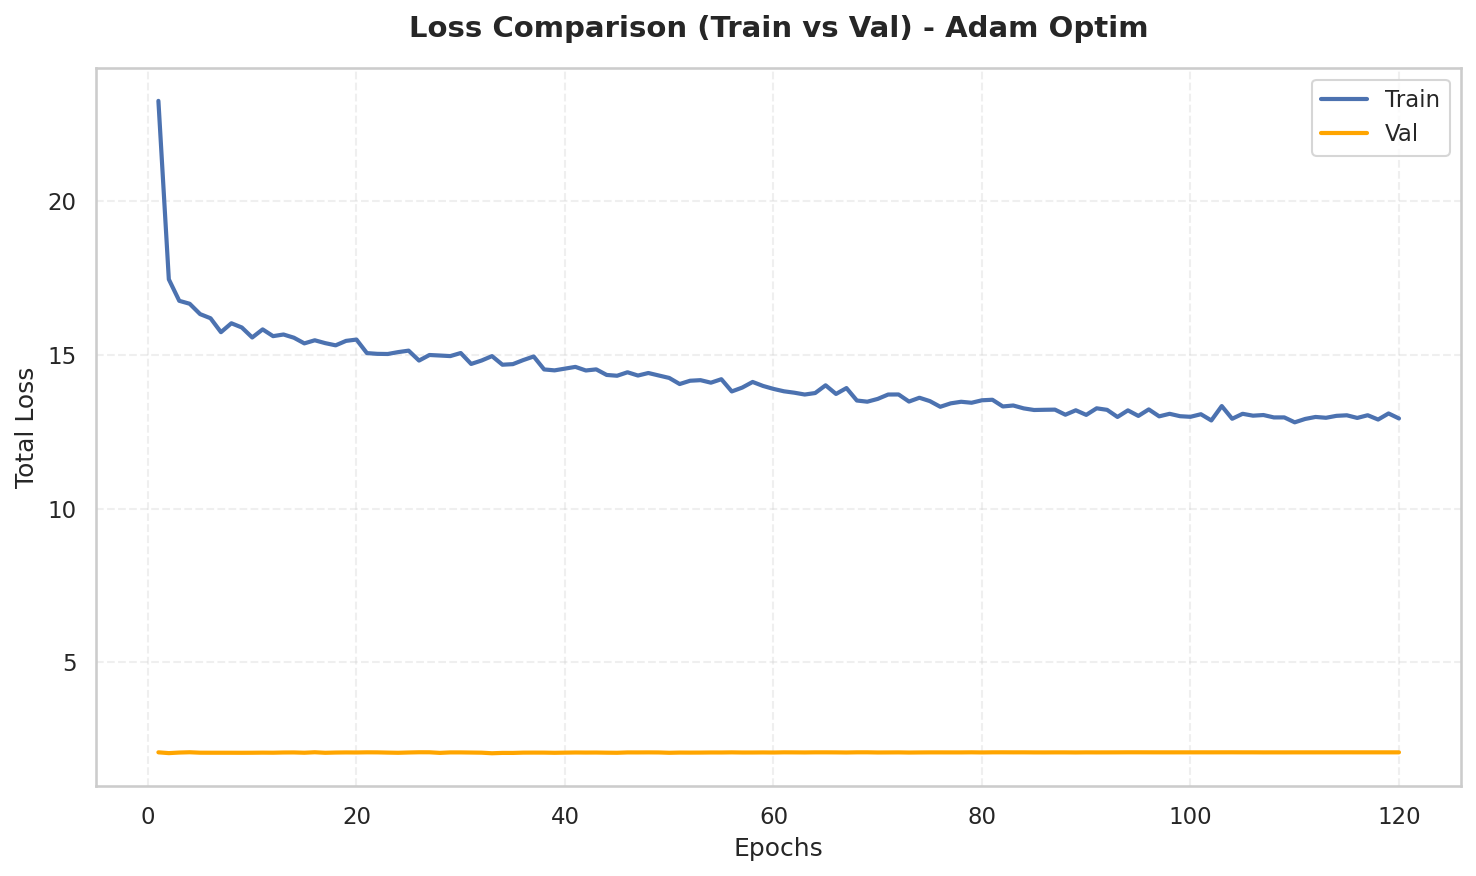

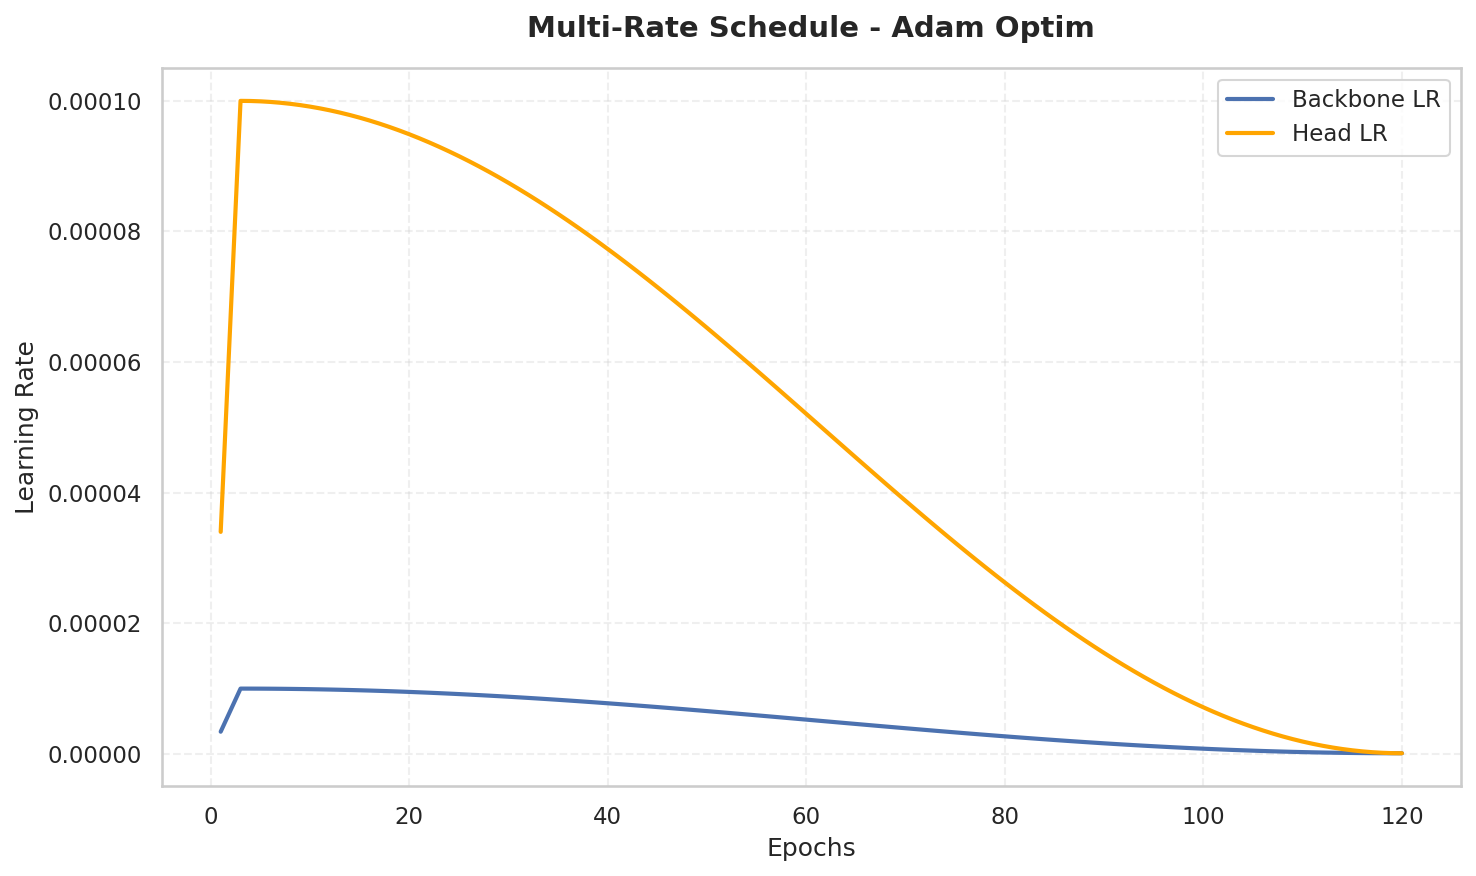

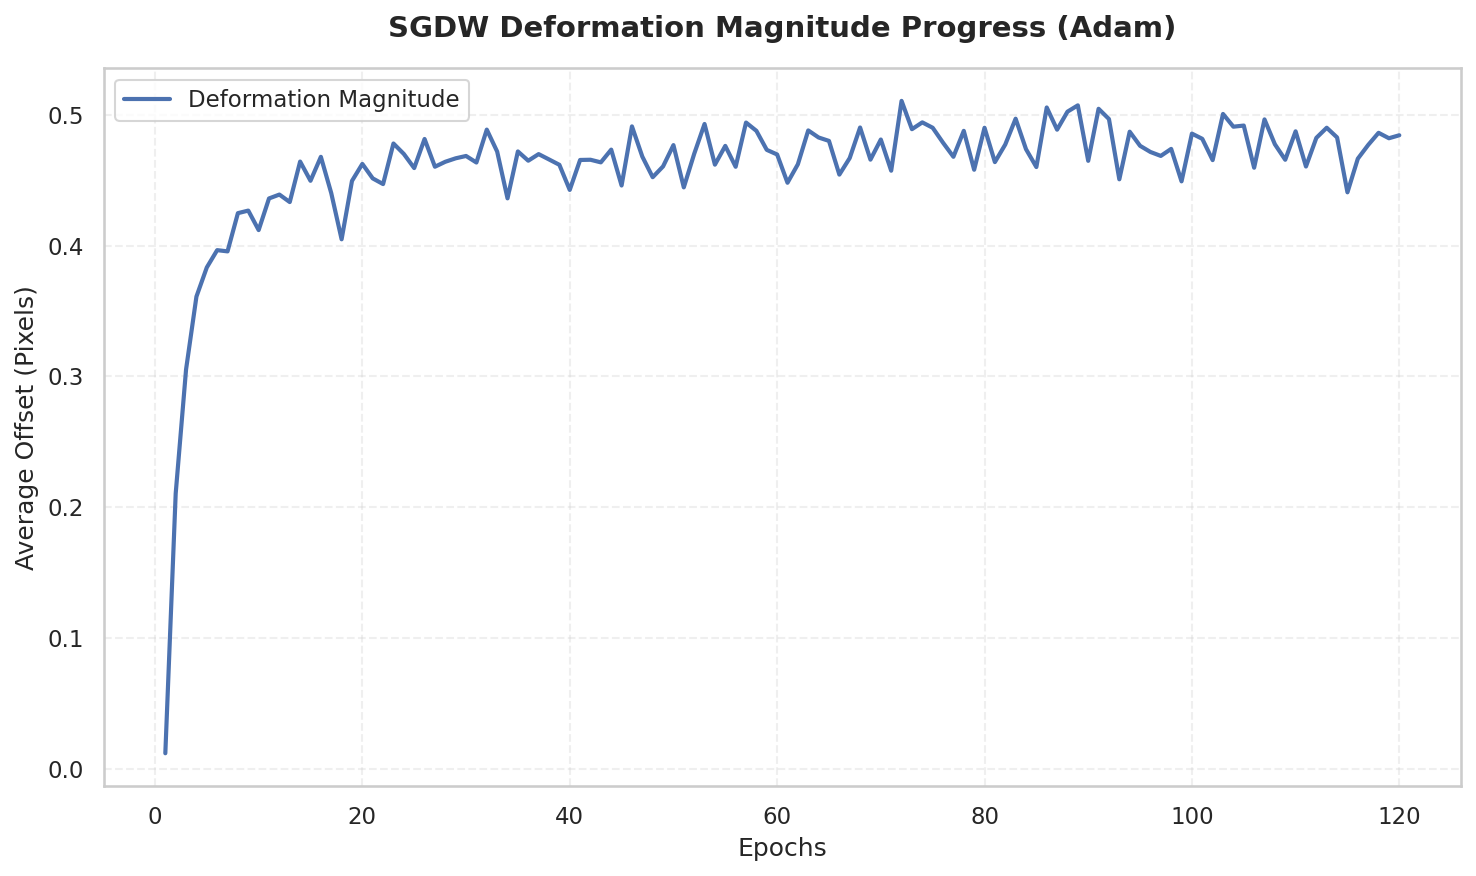

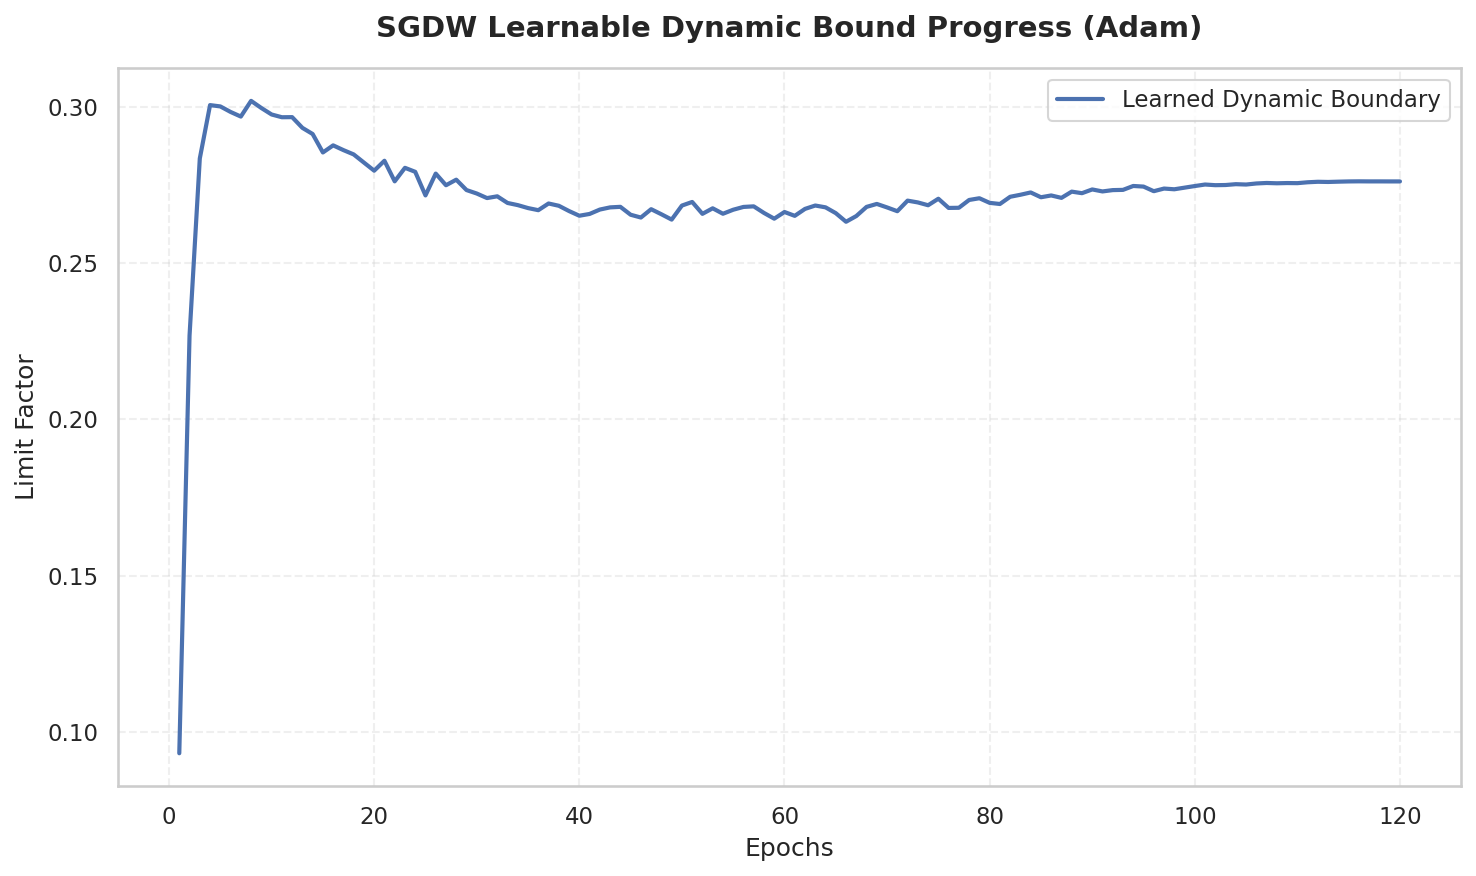

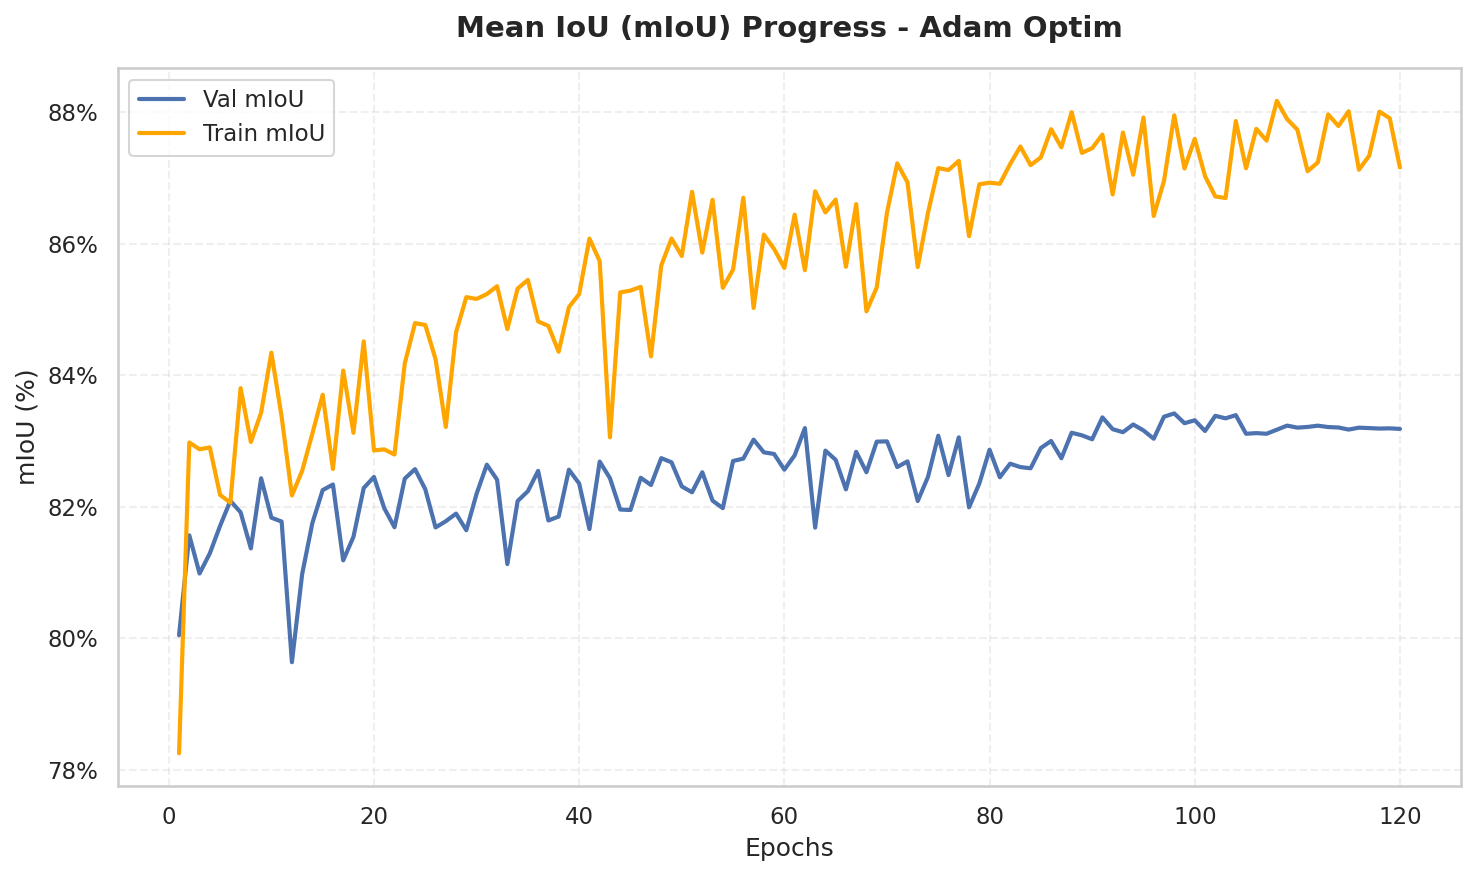

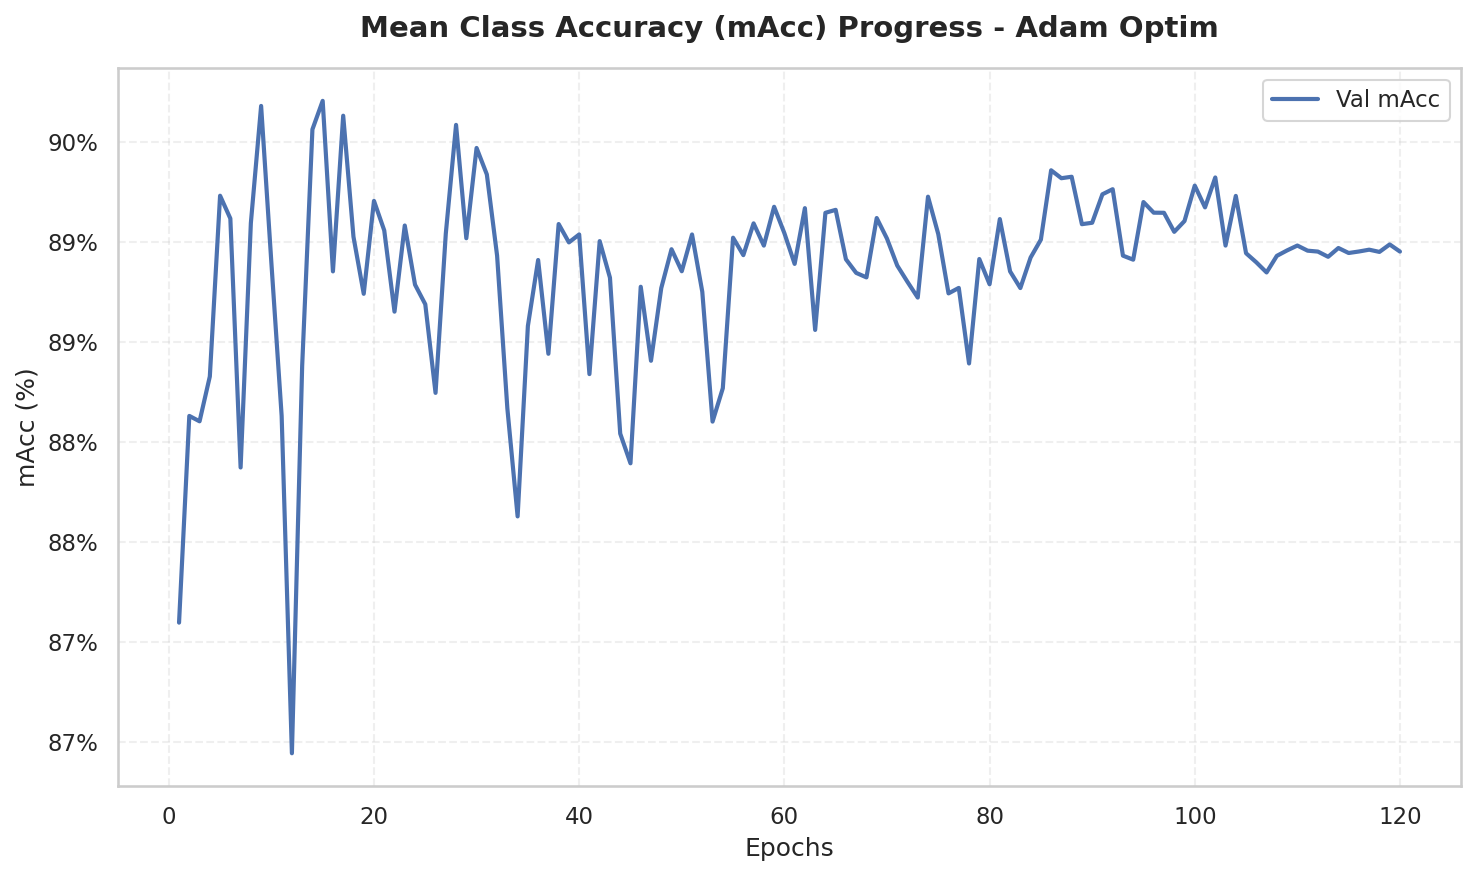

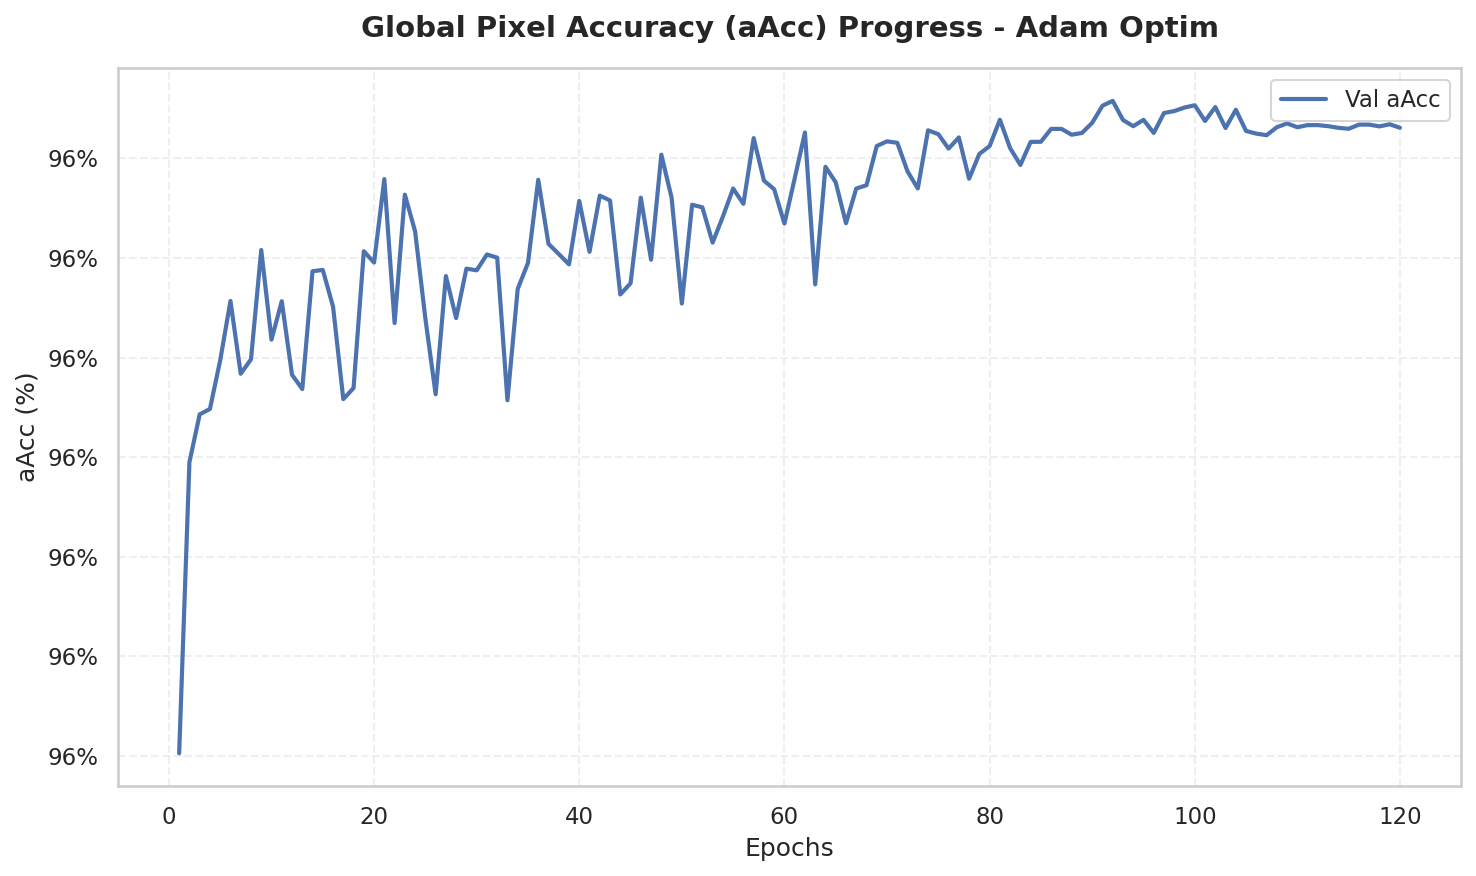

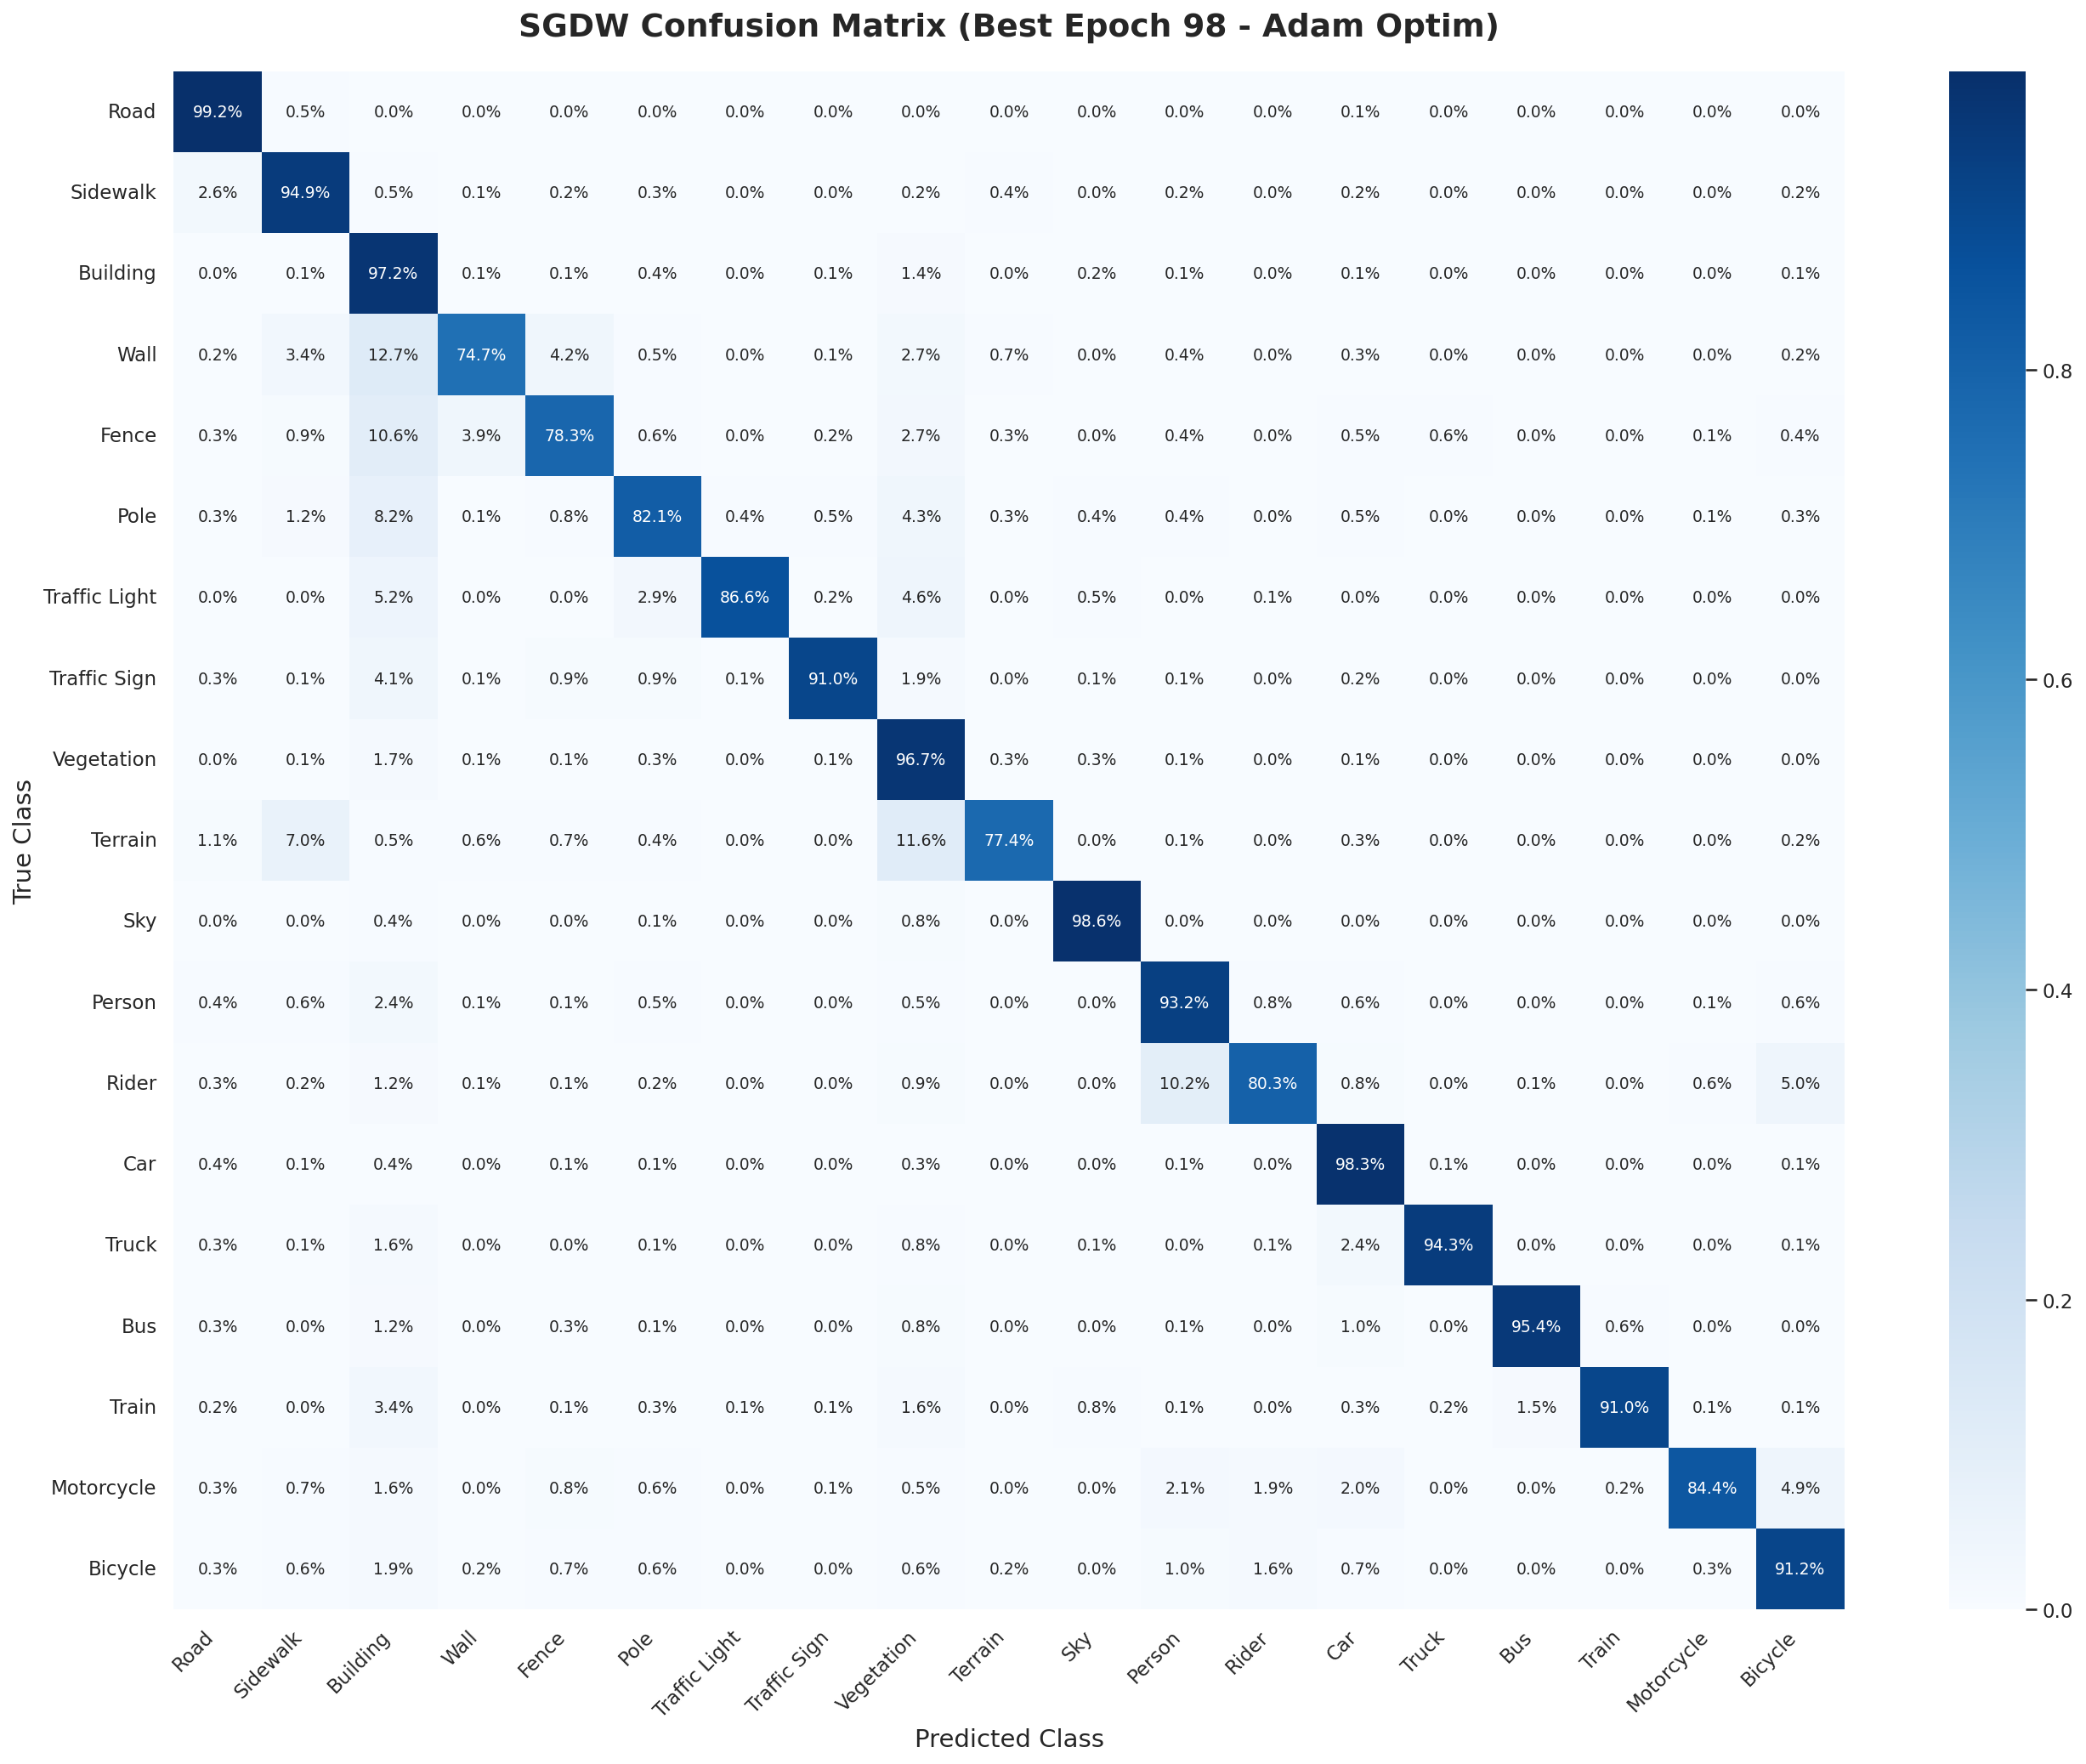


------------------------------------------------------------
Architecture: Multi-Scale SGDW with Dynamic Bounding (Adam Optim)
Decoder: Mask2Former (Bipartite Native)
Backbone: Swin-Small
Total Parameters:      70,377,100  (70.38 M)
Trainable Parameters:  70,376,524  (70.38 M)
------------------------------------------------------------
SUCCESS: All artifacts and graphs routed to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export

FINAL RESULTS (Multi-Scale SGDW Architecture - Adam Optim)
Best Validation mIoU:           83.42% (Epoch 98)
Final Epoch Pixel Acc (aAcc):   96.93%
Final Epoch Mean IoU (mIoU):    83.18%
Final Epoch Mean Class Acc:     89.45%
Total Training Time:            2 days, 17:42:40
------------------------------------------------------------
CLASS NAME           | IoU (%)    | Accuracy (%)
------------------------------------------------------------
Road                 | 98.71      | 99.24     
Sidewalk           

In [7]:
# ============================================================
# STEP 6: EXPORT RESULTS, PLOTS, CONFUSION MATRIX, FINAL SUMMARY
# Target Architecture: SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim
# Target Dataset: Cityscapes
# Optimized for: Automated Matrix Reconstruction, Class-Wise Parsing, 
# Percentage Matrices, Continuous Metric Plotting (Ablation: Adam Optim)
# ============================================================

import os
import json
from pathlib import Path
from datetime import timedelta

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch.nn.functional as F

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = [
    "history", "model", "CLASS_NAMES", "CLASSES",
    "CHECKPOINT_DIR", "best_record", "DEVICE"
]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

IGNORE_INDEX = globals().get("IGNORE_INDEX", 255)
FINAL_SAVE_DIR = globals().get(
    "FINAL_SAVE_DIR", 
    Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export")
)
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Final export directory validated: {FINAL_SAVE_DIR.resolve()}\n")

# ------------------------------------------------------------
# AUTOMATED MATRIX RECOVERY PROTOCOL (CRASH PROOF)
# ------------------------------------------------------------
BEST_CONF_MATRIX = globals().get("best_conf_matrix", globals().get("val_conf_matrix", None))

if BEST_CONF_MATRIX is None and "val_loader" in globals() and "model" in globals():
    print("[!] Confusion matrix missing from RAM. Reconstructing from Best Checkpoint...")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, "best_model_sgdw_cs_adam.pt")
    if not os.path.exists(best_ckpt_path):
        best_ckpt_path = best_record.get("best_path", str(CHECKPOINT_DIR / "best_model_sgdw_cs_adam.pt"))
    
    if os.path.exists(best_ckpt_path):
        ckpt = torch.load(best_ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        model.eval()
        
        reconstructed_cm = np.zeros((CLASSES, CLASSES), dtype=np.int64)
        
        def _fast_confusion_matrix(y_true, y_pred, num_classes):
            idx = num_classes * y_true + y_pred
            return np.bincount(idx, minlength=num_classes**2).reshape(num_classes, num_classes)

        def _build_semantic_targets(mask_labels, class_labels, image_size):
            H, W = image_size
            targets = torch.full((len(mask_labels), H, W), fill_value=IGNORE_INDEX, dtype=torch.long, device=mask_labels[0].device)
            for b in range(len(mask_labels)):
                if class_labels[b].numel() == 0: continue
                for inst_idx, cls_id in enumerate(class_labels[b]):
                    if int(cls_id.item()) == IGNORE_INDEX: continue
                    targets[b][mask_labels[b][inst_idx] > 0.5] = int(cls_id.item())
            return targets
        
        USE_AMP = torch.cuda.is_available()
        pbar = tqdm(val_loader, total=len(val_loader), desc="Reconstructing Metrics (TTA)", leave=False)
        
        with torch.no_grad():
            for images, mask_labels, class_labels in pbar:
                images = images.to(DEVICE, non_blocking=True)
                _, _, val_h, val_w = images.shape
                
                mask_labels = [m.to(DEVICE, non_blocking=True) for m in mask_labels]
                class_labels = [c.to(DEVICE, non_blocking=True) for c in class_labels]
                dense_targets = _build_semantic_targets(mask_labels, class_labels, (val_h, val_w))

                scales = [0.75, 1.0, 1.25]
                final_logits = torch.zeros((images.shape[0], CLASSES, val_h, val_w), device=DEVICE, dtype=torch.float32)
                
                for scale in scales:
                    sH, sW = (int(val_h * scale) // 32) * 32, (int(val_w * scale) // 32) * 32 
                    scaled_img = F.interpolate(images, size=(sH, sW), mode='bilinear', align_corners=False)
                    
                    with torch.autocast(device_type="cuda", enabled=USE_AMP):
                        outputs = model(pixel_values=scaled_img)
                        m_preds = F.interpolate(outputs.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls = F.softmax(outputs.class_queries_logits, dim=-1)[..., :-1]
                        final_logits += torch.einsum("bqc,bqhw->bchw", m_cls, m_preds.sigmoid()).float()
                        
                        outputs_f = model(pixel_values=torch.flip(scaled_img, dims=[3]))
                        m_preds_f = F.interpolate(outputs_f.masks_queries_logits, size=(val_h, val_w), mode="bilinear", align_corners=False)
                        m_cls_f = F.softmax(outputs_f.class_queries_logits, dim=-1)[..., :-1]
                        flip_logits = torch.einsum("bqc,bqhw->bchw", m_cls_f, m_preds_f.sigmoid())
                        final_logits += torch.flip(flip_logits, dims=[3]).float()
                        
                semantic_logits = final_logits / (len(scales) * 2)
                
                preds = torch.argmax(semantic_logits, dim=1).cpu().numpy().astype(np.int64)
                targets_np = dense_targets.cpu().numpy().astype(np.int64)
                valid = (targets_np != IGNORE_INDEX)
                if valid.any():
                    reconstructed_cm += _fast_confusion_matrix(targets_np[valid], preds[valid], CLASSES)
                    
        BEST_CONF_MATRIX = reconstructed_cm
        print("[*] Reconstruction Complete! Restoring class-wise scores.")
    else:
        print("[!] Could not locate best checkpoint on disk. Class-wise metrics will remain empty.")

# ------------------------------------------------------------
# BUILD MAIN DATAFRAME
# ------------------------------------------------------------
num_epochs = len(history["epoch"])

def get_hist_col(key, fallback_key=None):
    col = history.get(key, [])
    if len(col) == num_epochs: return col
    if fallback_key and len(history.get(fallback_key, [])) == num_epochs: return history[fallback_key]
    if len(col) > 0:
        return col + [np.nan] * (num_epochs - len(col)) if len(col) < num_epochs else col[:num_epochs]
    return [np.nan] * num_epochs

df = pd.DataFrame({
    "Epoch": get_hist_col("epoch"),
    "Phase": get_hist_col("phase"),
    "Train_Total_Loss": get_hist_col("train_total_loss"),
    "Train_mIoU": get_hist_col("train_miou"),
    "Val_Total_Loss": get_hist_col("val_total_loss"),
    "Val_mIoU": get_hist_col("val_miou"),
    "Val_mAcc": get_hist_col("val_macc"),
    "Val_aAcc": get_hist_col("val_aacc"),
    "LR_Backbone": get_hist_col("backbone_lr"),
    "LR_Head": get_hist_col("head_lr"),
    "SGDW_Offset_Magnitude": get_hist_col("sgdw_offset_magnitude"),
    "SGDW_Dynamic_Bound": get_hist_col("sgdw_dynamic_bound"), 
    "Epoch_Time_sec": get_hist_col("epoch_time_sec"),
})

total_training_time_sec = float(df["Epoch_Time_sec"].sum()) if not df["Epoch_Time_sec"].isna().all() else 0.0
total_time_str = str(timedelta(seconds=int(total_training_time_sec)))
df["Total_Training_Session_Time"] = total_time_str

# ------------------------------------------------------------
# PREPARE CLASS-WISE DATA
# ------------------------------------------------------------
class_wise_data = []
if BEST_CONF_MATRIX is not None:
    tp = np.diag(BEST_CONF_MATRIX)
    fp = BEST_CONF_MATRIX.sum(axis=0) - tp
    fn = BEST_CONF_MATRIX.sum(axis=1) - tp
    
    iou_per_class = tp / (tp + fp + fn + 1e-10)
    acc_per_class = tp / (tp + fn + 1e-10)
    
    for i, name in enumerate(CLASS_NAMES):
        class_wise_data.append({
            "Class Name": name,
            "IoU (%)": float(iou_per_class[i] * 100),
            "Accuracy (%)": float(acc_per_class[i] * 100)
        })

# ------------------------------------------------------------
# EXPORT FINAL RESULTS CSV & EXCEL
# ------------------------------------------------------------
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val if val > 1.0 else val * 100.0

final_v_acc = safe_pct(df["Val_aAcc"].iloc[-1]) if not df.empty else 0.0
final_mIoU = safe_pct(df["Val_mIoU"].iloc[-1]) if not df.empty else 0.0
final_mAcc = safe_pct(df["Val_mAcc"].iloc[-1]) if not df.empty else 0.0

if "val_miou" in history and len(history["val_miou"]) > 0:
    best_miou_raw = max(history["val_miou"])
    best_idx = history["val_miou"].index(best_miou_raw)
    best_epoch = history["epoch"][best_idx]
    best_miou = safe_pct(best_miou_raw)
else:
    best_epoch = best_record.get("best_epoch", -1)
    best_miou = safe_pct(best_record.get("best_miou", 0.0))

final_global_data = [
    {"Metric": "Best Validation mIoU", "Value": f"{best_miou:.2f}%"},
    {"Metric": "Global Pixel Accuracy (aAcc)", "Value": f"{final_v_acc:.2f}%"},
    {"Metric": "Final Epoch Mean IoU (mIoU)", "Value": f"{final_mIoU:.2f}%"},
    {"Metric": "Final Epoch Mean Class Accuracy (mAcc)", "Value": f"{final_mAcc:.2f}%"},
    {"Metric": "Total Training Time", "Value": total_time_str}
]
pd.DataFrame(final_global_data).to_csv(FINAL_SAVE_DIR / "finalresults_sgdw_adam.csv", index=False)

excel_path = FINAL_SAVE_DIR / "Training_Metrics_Report_SGDW_Adam.xlsx"
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df.to_excel(writer, sheet_name='Epoch_Metrics', index=False)
    if class_wise_data:
        pd.DataFrame(class_wise_data).to_excel(writer, sheet_name='Class_Wise_Results', index=False)

# ------------------------------------------------------------
# STANDARD SEPARATE PLOTS (INDIVIDUAL METRICS)
# ------------------------------------------------------------
sns.set_style("whitegrid")

def save_separate_plot(filename, title, ylabel, train_data, val_data=None, label1="Train", label2="Val"):
    plt.figure(figsize=(10, 6))
    
    epochs_range = range(1, len(train_data) + 1)
    train_clean = np.array(train_data, dtype=float)
    
    if not np.isnan(train_clean).all():
        plt.plot(epochs_range, train_clean, label=label1, lw=2)
    
    if val_data is not None:
        val_clean = np.array(val_data, dtype=float)
        if not np.isnan(val_clean).all():
            plt.plot(epochs_range, val_clean, label=label2, lw=2, color='orange')
            
    if "(%)" in ylabel:
        plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}%".format(int(x))))

    plt.title(title, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Epochs", fontsize=12)
    plt.ylabel(ylabel, fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / f"{filename}.png", dpi=600, bbox_inches='tight')
    plt.show() 
    plt.close()

# Extract Data
train_loss = df["Train_Total_Loss"].tolist()
val_loss = df["Val_Total_Loss"].tolist()
offset_magnitude = df["SGDW_Offset_Magnitude"].tolist()
dynamic_bound = df["SGDW_Dynamic_Bound"].tolist()

def ensure_percentage(series):
    if series.isna().all(): return None
    data = series.tolist()
    return [x * 100 if (x is not None and x <= 1.0) else x for x in data]

train_miou = ensure_percentage(df["Train_mIoU"])
val_miou = ensure_percentage(df["Val_mIoU"])
val_aacc = ensure_percentage(df["Val_aAcc"])
val_macc = ensure_percentage(df["Val_mAcc"])

lr_backbone = df["LR_Backbone"].tolist()
lr_head = df["LR_Head"].tolist()

# 1. Loss & Mechanics Plots
save_separate_plot("loss_comparison_adam", "Loss Comparison (Train vs Val) - Adam Optim", "Total Loss", train_loss, val_loss)
save_separate_plot("learning_rate_progress_adam", "Multi-Rate Schedule - Adam Optim", "Learning Rate", lr_backbone, lr_head, label1="Backbone LR", label2="Head LR")
if not df["SGDW_Offset_Magnitude"].isna().all():
    save_separate_plot("sgdw_offset_magnitude_adam", "SGDW Deformation Magnitude Progress (Adam)", "Average Offset (Pixels)", offset_magnitude, label1="Deformation Magnitude")
if not df["SGDW_Dynamic_Bound"].isna().all():
    save_separate_plot("sgdw_dynamic_bound_adam", "SGDW Learnable Dynamic Bound Progress (Adam)", "Limit Factor", dynamic_bound, label1="Learned Dynamic Boundary")

# 2. Individual Evaluation Metric Plots
save_separate_plot("miou_progress_adam", "Mean IoU (mIoU) Progress - Adam Optim", "mIoU (%)", val_miou, train_miou, label1="Val mIoU", label2="Train mIoU")
save_separate_plot("macc_progress_adam", "Mean Class Accuracy (mAcc) Progress - Adam Optim", "mAcc (%)", val_macc, label1="Val mAcc")
save_separate_plot("aacc_progress_adam", "Global Pixel Accuracy (aAcc) Progress - Adam Optim", "aAcc (%)", val_aacc, label1="Val aAcc")

# ------------------------------------------------------------
# PERCENTAGE-BASED CONFUSION MATRIX
# ------------------------------------------------------------
if BEST_CONF_MATRIX is not None:
    plt.figure(figsize=(18, 14)) 
    
    cm_normalized = BEST_CONF_MATRIX.astype('float') / (BEST_CONF_MATRIX.sum(axis=1)[:, np.newaxis] + 1e-10)
    
    sns.heatmap(
        cm_normalized, annot=True, fmt='.1%', cmap='Blues', 
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, 
        annot_kws={"size": 9}
    ) 
    
    plt.title(f"SGDW Confusion Matrix (Best Epoch {best_epoch} - Adam Optim)", fontsize=18, fontweight='bold', pad=20)
    plt.ylabel('True Class', fontsize=14)
    plt.xlabel('Predicted Class', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig(FINAL_SAVE_DIR / "confusion_matrix_percentages_adam.png", dpi=600, bbox_inches='tight')
    plt.show() 
    plt.close()

# ------------------------------------------------------------
# FINAL PRINT SUMMARY
# ------------------------------------------------------------
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n" + "-"*60)
print(f"Architecture: Multi-Scale SGDW with Dynamic Bounding (Adam Optim)")
print(f"Decoder: Mask2Former (Bipartite Native)")
print(f"Backbone: Swin-Small")
print(f"Total Parameters:      {total_params:,}  ({total_params/1e6:.2f} M)")
print(f"Trainable Parameters:  {trainable_params:,}  ({trainable_params/1e6:.2f} M)")
print(f"-"*60)
print(f"SUCCESS: All artifacts and graphs routed to:\n{FINAL_SAVE_DIR.resolve()}")
print("\n" + "="*60)
print(f"FINAL RESULTS (Multi-Scale SGDW Architecture - Adam Optim)")
print("="*60)
print(f"Best Validation mIoU:           {best_miou:.2f}% (Epoch {best_epoch})")
print(f"Final Epoch Pixel Acc (aAcc):   {final_v_acc:.2f}%")
print(f"Final Epoch Mean IoU (mIoU):    {final_mIoU:.2f}%")
print(f"Final Epoch Mean Class Acc:     {final_mAcc:.2f}%")
print(f"Total Training Time:            {total_time_str}")
print("-" * 60)
print(f"{'CLASS NAME':<20} | {'IoU (%)':<10} | {'Accuracy (%)':<10}")
print("-" * 60)

if class_wise_data:
    for item in class_wise_data:
        print(f"{item['Class Name']:<20} | {item['IoU (%)']:<10.2f} | {item['Accuracy (%)']:<10.2f}")

Presentation graph will be exported to: /home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export
[*] Filtered presentation graph saved successfully to:
/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export/presentation_metrics_progress_sgdw_adam.png


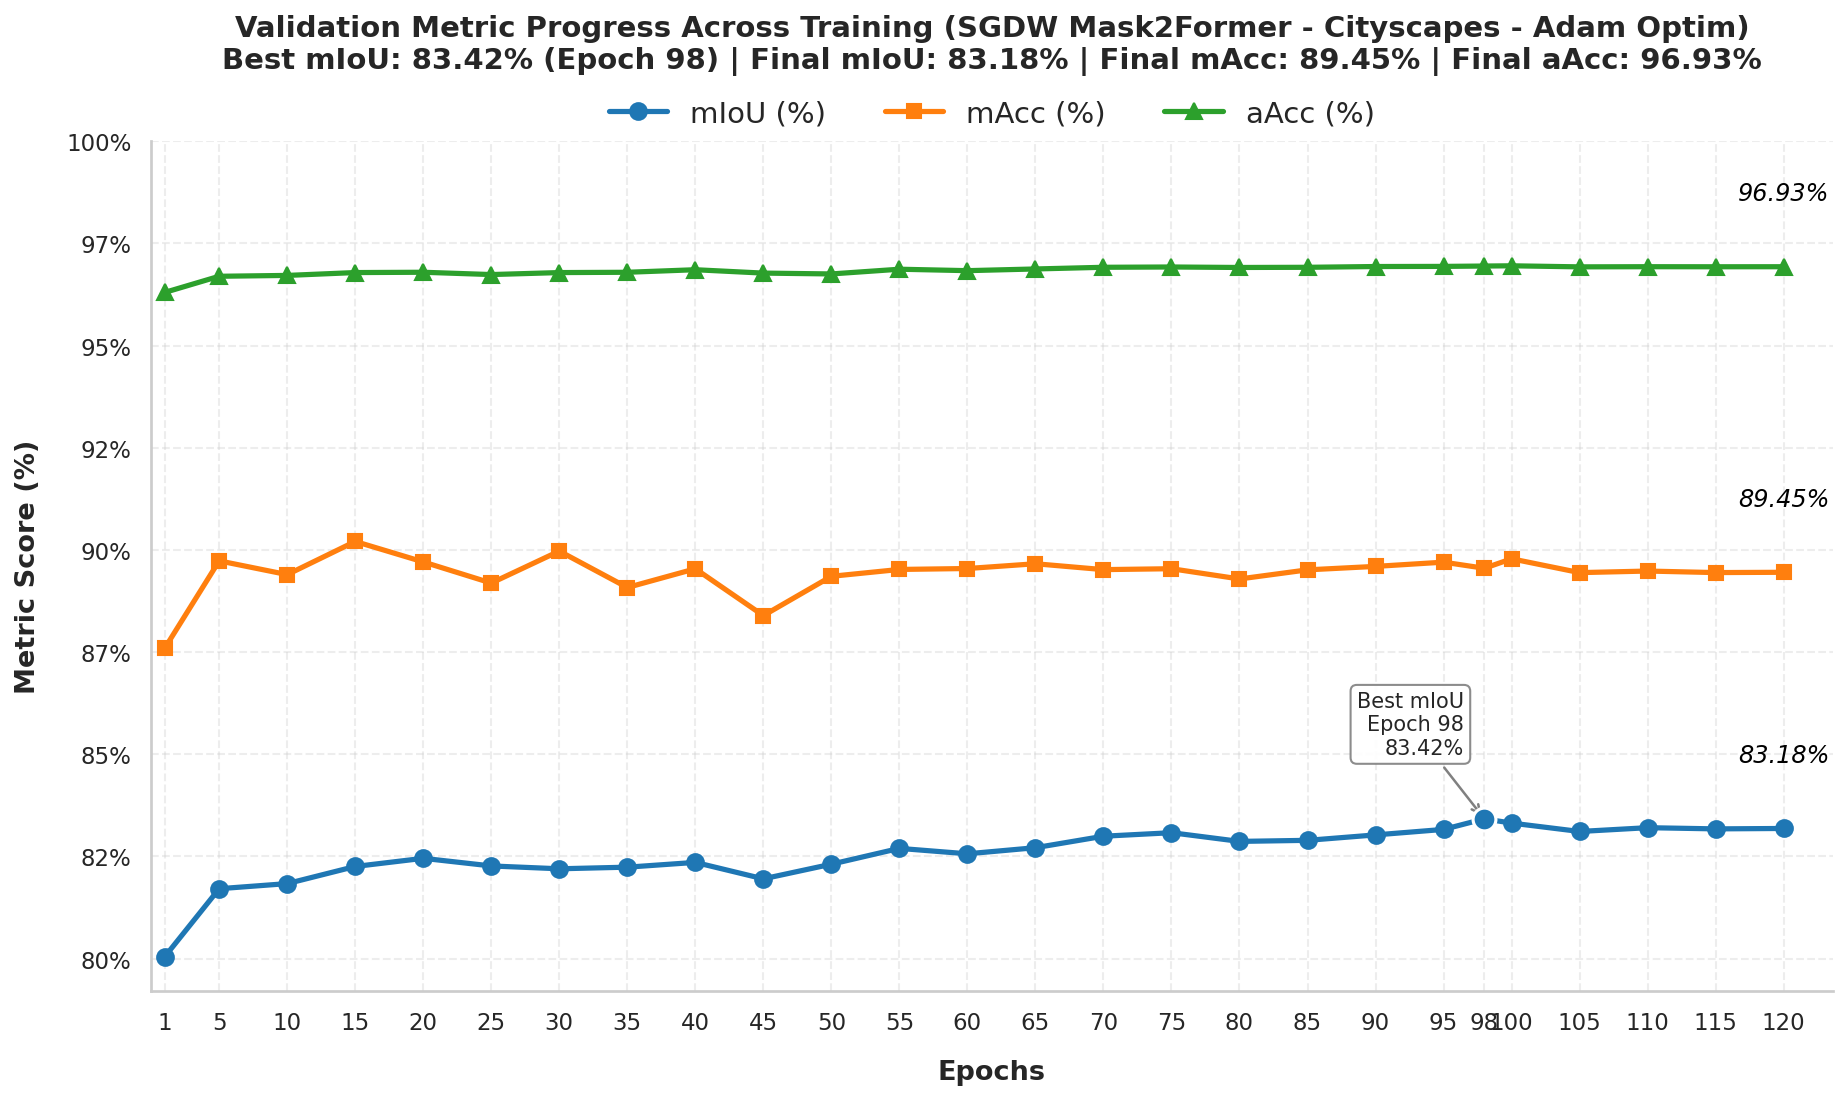

In [8]:
# ============================================================
# STEP 7: PRESENTATION-READY MULTI-METRIC PROGRESS GRAPH
# Target Architecture: Semantically-Guided Deformable Windows (SGDW) Swin-Small
# Target Dataset: Cityscapes
# Optimized for: Global Path Inheritance, Specific Epoch Intervals,
# and Strict Percentage Scaling for Publication (Ablation: Adam Optim)
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# SAFETY CHECKS & PATH INHERITANCE
# ------------------------------------------------------------
required_globals = ["history"]
missing = [k for k in required_globals if k not in globals()]
if missing:
    raise NameError(f"Missing required variables from previous steps: {missing}")

if "val_miou" not in history or len(history["val_miou"]) == 0:
    raise ValueError("history['val_miou'] is empty. Run training (Step 5) before Step 7.")

# Inherit the centralized export directory securely from Step 1
FINAL_SAVE_DIR = globals().get(
    "FINAL_SAVE_DIR", 
    Path("/home/hrusikesh-nishank/Pictures/SwinSmall_Mask2Former_SGDW_PixelDecoder_CS_adam_optim/Results_Export")
)
FINAL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"Presentation graph will be exported to: {FINAL_SAVE_DIR.resolve()}")

# ------------------------------------------------------------
# PREPARE EPOCHS & DATA
# ------------------------------------------------------------
all_epochs = history["epoch"]
PLOT_INTERVAL = 5

# Safe percentage converter (prevents 80% turning into 8000% if already scaled in Step 5)
def safe_pct(val):
    if pd.isna(val) or np.isnan(val): return 0.0
    return val * 100.0 if val <= 1.0 else float(val)

# Bulletproof Best Epoch Extraction
best_miou_raw = max(history["val_miou"])
best_idx = history["val_miou"].index(best_miou_raw)
best_miou = safe_pct(best_miou_raw)
best_miou_epoch = all_epochs[best_idx]

# Filter epochs to reduce visual clutter: Epoch 1, every nth epoch, best epoch, final epoch
filtered_epochs_set = set([e for e in all_epochs if e == 1 or e % PLOT_INTERVAL == 0] + [all_epochs[-1], best_miou_epoch])
filtered_epochs = sorted(list(filtered_epochs_set))

indices = [all_epochs.index(e) for e in filtered_epochs]

# Extract and convert to percentages for cleaner presentation
miou_scores = [safe_pct(history["val_miou"][i]) for i in indices]
macc_scores = [safe_pct(history["val_macc"][i]) for i in indices]
aacc_scores = [safe_pct(history["val_aacc"][i]) for i in indices]

final_miou = safe_pct(history["val_miou"][-1])
final_macc = safe_pct(history["val_macc"][-1])
final_aacc = safe_pct(history["val_aacc"][-1])
final_x = all_epochs[-1]

# ------------------------------------------------------------
# PLOT SETUP 
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12.5, 7.5)) 

color_miou = '#1f77b4'  # Blue
color_macc = '#ff7f0e'  # Orange
color_aacc = '#2ca02c'  # Green

ax.plot(filtered_epochs, miou_scores, marker='o', linewidth=2.5, markersize=8, label='mIoU (%)', color=color_miou)
ax.plot(filtered_epochs, macc_scores, marker='s', linewidth=2.5, markersize=7, label='mAcc (%)', color=color_macc)
ax.plot(filtered_epochs, aacc_scores, marker='^', linewidth=2.5, markersize=8, label='aAcc (%)', color=color_aacc)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------
ax.set_xlabel('Epochs', fontsize=13, fontweight='bold', labelpad=12)
ax.set_ylabel('Metric Score (%)', fontsize=13, fontweight='bold', labelpad=12)
ax.set_xticks(filtered_epochs)

# Force the Y-axis to display percent signs natively
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x)}%"))

# ------------------------------------------------------------
# BEST mIoU ANNOTATION 
# ------------------------------------------------------------
ax.scatter(best_miou_epoch, best_miou, s=120, zorder=5, color=color_miou, edgecolors='white', linewidth=1.5)

if best_miou_epoch <= (max(filtered_epochs) * 0.6):
    best_text_x = best_miou_epoch + 1.5
    best_ha = "left"
else:
    best_text_x = best_miou_epoch - 1.5
    best_ha = "right"

ax.annotate(
    f'Best mIoU\nEpoch {best_miou_epoch}\n{best_miou:.2f}%',
    xy=(best_miou_epoch, best_miou),
    xytext=(best_text_x, best_miou + 1.5),
    fontsize=10, ha=best_ha, va='bottom',
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
    arrowprops=dict(arrowstyle='->', color='gray', lw=1.2)
)

# ------------------------------------------------------------
# END-OF-LINE FINAL VALUE ANNOTATIONS (Floating above markers)
# ------------------------------------------------------------
# Placed slightly above the final points to match the target aesthetic
offset_y = 1.5

ax.text(final_x, final_miou + offset_y, f'{final_miou:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_macc + offset_y, f'{final_macc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')
ax.text(final_x, final_aacc + offset_y, f'{final_aacc:.2f}%', va='bottom', ha='center', fontsize=11.5, fontstyle='italic', color='black')

ax.set_xlim(left=0, right=max(all_epochs) + (max(all_epochs) * 0.03))
ax.set_ylim(top=100) 

# ------------------------------------------------------------
# STYLING & LEGEND
# ------------------------------------------------------------
# Center the legend horizontally above the plot area
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False, fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.3)
ax.spines['left'].set_linewidth(1.3)

ax.grid(True, linestyle='--', alpha=0.35)

title_main = "Validation Metric Progress Across Training (SGDW Mask2Former - Cityscapes - Adam Optim)"
title_sub = f"Best mIoU: {best_miou:.2f}% (Epoch {best_miou_epoch}) | Final mIoU: {final_miou:.2f}% | Final mAcc: {final_macc:.2f}% | Final aAcc: {final_aacc:.2f}%"

# Pushed the title up slightly to make room for the new legend position
ax.set_title(
    title_main + "\n" + title_sub,
    fontsize=14, fontweight='bold', pad=35
)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------
# Directly save the single, unified presentation-ready graph
combined_graph_path = FINAL_SAVE_DIR / "presentation_metrics_progress_sgdw_adam.png"
plt.savefig(combined_graph_path, dpi=600, bbox_inches='tight')
print(f"[*] Filtered presentation graph saved successfully to:\n{combined_graph_path.resolve()}")

plt.show()
plt.close()